In [5]:
import jax.numpy as jnp
from jax import vmap
import numpy as np

class PiecewiseLinearPolynomialsHex:
    def __init__(self, N_t, N_x, N_y, t_min=0.0, t_max=1.0, x_min=-1.0, x_max=1.0, y_min=-1.0, y_max=1.0, gauss_order=3, bdry_order=3):
        """
        Initialize piecewise linear polynomials on a hexahedral mesh with custom ranges.

        Args:
            N_t: Number of divisions along the t-axis.
            N_x: Number of divisions along the x-axis.
            N_y: Number of divisions along the y-axis.
            t_min: Minimum value for t (default: 0.0).
            t_max: Maximum value for t (default: 1.0).
            x_min: Minimum value for x (default: -1.0).
            x_max: Maximum value for x (default: 1.0).
            y_min: Minimum value for y (default: -1.0).
            y_max: Maximum value for y (default: 1.0).
            gauss_order: Order of Gauss quadrature (number of points per direction, default: 3).
            bdry_order: Order of boundary quadrature (number of points per face direction, default: 3).
        """
        self.N_t = N_t
        self.N_x = N_x
        self.N_y = N_y
        self.t_min = t_min
        self.t_max = t_max
        self.x_min = x_min
        self.x_max = x_max
        self.y_min = y_min
        self.y_max = y_max
        self.gauss_order = gauss_order
        self.bdry_order = bdry_order
        self.N_elements = N_t * N_x * N_y  # Number of hexahedra
        self.partitions = self._generate_hexahedra()
        self.coeffs = jnp.zeros((self.N_elements, 4))  # Coefficients a + b*t + c*x + d*y per hexahedron
        self.quad_points, self.quad_weights, self.element_indices, self.quad_points_parti, self.quad_weights_parti = self._setup_quadrature()
        # self.bdry_points_parti, self.bdry_weights_parti = self.get_boundary_quadrature()
        # self.normals = self.compute_normals()

    def _generate_hexahedra(self):
        """Generate the hexahedra for the mesh with custom ranges."""
        self.tau = (self.t_max - self.t_min) / self.N_t
        self.hx = (self.x_max - self.x_min) / self.N_x
        self.hy = (self.y_max - self.y_min) / self.N_y
        t_starts = jnp.linspace(self.t_min, self.t_max - self.tau, self.N_t)
        x_starts = jnp.linspace(self.x_min, self.x_max - self.hx, self.N_x)
        y_starts = jnp.linspace(self.y_min, self.y_max - self.hy, self.N_y)
        tl, xl, yl = jnp.meshgrid(t_starts, x_starts, y_starts, indexing='ij')
        # Define the 8 vertices for each hexahedron using binary offsets
        offsets_bin = jnp.array([[int(b) for b in f'{i:03b}'] for i in range(8)], dtype=jnp.float32)  # (8,3) binary 000 to 111
        deltas = jnp.array([self.tau, self.hx, self.hy])
        offsets = offsets_bin * deltas  # (8,3)
        lowers = jnp.stack([tl.ravel(), xl.ravel(), yl.ravel()], axis=1)[:, None, :]  # (N_elements, 1, 3)
        partitions = lowers + offsets[None, :, :]  # (N_elements, 8, 3)
        return partitions
        
    def _setup_quadrature(self):
        """
        Setup Gauss quadrature points and weights for hexahedral mesh.

        Returns:
            quad_points: Quadrature points, shape (N_quad, 3).
            quad_weights: Quadrature weights, shape (N_quad,).
            element_indices: Indices of hexahedra, shape (N_quad,).
            quad_points_parti: Quadrature points per hexahedron, shape (N_elements, Nq, 3).
            quad_weights_parti: Quadrature weights per hexahedron, shape (N_elements, Nq).
        """
        Nq = self.gauss_order ** 3  # Number of quadrature points per hexahedron

        # Gauss-Legendre nodes and weights in [-1, 1]
        nodes, weights = np.polynomial.legendre.leggauss(self.gauss_order)
        nodes_jnp = jnp.array(nodes)
        weights_jnp = jnp.array(weights)

        # Tensor product for 3D
        t_nodes, x_nodes, y_nodes = jnp.meshgrid(nodes_jnp, nodes_jnp, nodes_jnp)
        t_weights, x_weights, y_weights = jnp.meshgrid(weights_jnp, weights_jnp, weights_jnp)
        quad_weights_3d = (t_weights * x_weights * y_weights).ravel()

        # Function to map [-1,1]^3 to hexahedron [t_low, t_high]x[x_low, x_high]x[y_low, y_high]
        def map_to_hex(hex):
            t_low, x_low, y_low = hex[0]
            t_high, x_high, y_high = hex[-1]
            t_scale = (t_high - t_low) / 2
            x_scale = (x_high - x_low) / 2
            y_scale = (y_high - y_low) / 2
            t_center = (t_high + t_low) / 2
            x_center = (x_high + x_low) / 2
            y_center = (y_high + y_low) / 2
            t_points = t_center + t_nodes.ravel() * t_scale
            x_points = x_center + x_nodes.ravel() * x_scale
            y_points = y_center + y_nodes.ravel() * y_scale
            points = jnp.stack([t_points, x_points, y_points], axis=1)
            weights = quad_weights_3d * (t_scale * x_scale * y_scale)
            return points, weights

        # Vectorize over hexahedra
        quad_points_parti, quad_weights_parti = vmap(map_to_hex)(self.partitions)

        # Flatten for global quadrature
        quad_points = quad_points_parti.reshape(-1, 3)
        quad_weights = quad_weights_parti.reshape(-1)
        element_indices = jnp.repeat(jnp.arange(self.N_elements), Nq)

        return quad_points, quad_weights, element_indices, quad_points_parti, quad_weights_parti


In [19]:
import jax.numpy as jnp
from jax import vmap
import numpy as np
from scipy.integrate import tplquad
import math

# Define a complicated test function (non-polynomial to stress the quadrature)
def test_function(t, x, y):
    return jnp.sin(2 * jnp.pi * t) * jnp.cos(3 * jnp.pi * x) * jnp.exp(y) + t * x**2 * y**3 + jnp.log(1 + jnp.abs(t + x + y))

# Vectorized version for JAX quadrature points
def test_function_vec(points):
    t, x, y = points[:, 0], points[:, 1], points[:, 2]
    return test_function(t, x, y)

# SciPy version (uses NumPy)
def test_function_scipy(y, x, t):  # Order for tplquad: integrand(y, x, t) with dy dx dt
    return np.sin(2 * np.pi * t) * np.cos(3 * np.pi * x) * np.exp(y) + t * x**2 * y**3 + np.log(1 + np.abs(t + x + y))

# Function to compute quadrature integral
def compute_quadrature_integral(plph):
    return jnp.sum(test_function_vec(plph.quad_points) * plph.quad_weights)

# Function to compute SciPy integral (high accuracy)
def compute_scipy_integral(t_min, t_max, x_min, x_max, y_min, y_max):
    integral, error = tplquad(
        test_function_scipy,
        t_min, t_max,  # dt
        lambda t: x_min, lambda t: x_max,  # dx
        lambda t, x: y_min, lambda t, x: y_max,  # dy
        epsabs=1e-10, epsrel=1e-10
    )
    return integral, error

# Basic check: sum of weights should equal domain volume
def check_volume(plph, t_min, t_max, x_min, x_max, y_min, y_max):
    computed_volume = jnp.sum(plph.quad_weights)
    exact_volume = (t_max - t_min) * (x_max - x_min) * (y_max - y_min)
    print(f"Computed volume: {computed_volume}, Exact volume: {exact_volume}")
    return abs(computed_volume - exact_volume) < 1e-10

# Test with specific parameters
N_t, N_x, N_y = 3, 3, 3  # Small number of divisions for testing
t_min, t_max = 0.0, 1.0
x_min, x_max = -1.0, 1.0
y_min, y_max = -1.0, 1.0
gauss_order = 5  # Default

plph = PiecewiseLinearPolynomialsHex(N_t, N_x, N_y, t_min, t_max, x_min, x_max, y_min, y_max, gauss_order)

# Check volume
volume_check = check_volume(plph, t_min, t_max, x_min, x_max, y_min, y_max)
print(f"Volume check passed: {volume_check}")

# Compute integrals
quad_int = compute_quadrature_integral(plph)
# scipy_int, scipy_error = compute_scipy_integral(t_min, t_max, x_min, x_max, y_min, y_max)

print(f"Quadrature integral: {quad_int}")
print(f"SciPy integral: {scipy_int} (estimated error: {scipy_error})")

# Compare (difference should be small, depending on gauss_order and mesh refinement)
difference = abs(quad_int - scipy_int)
print(f"Absolute difference: {difference}")
print(f"Relative difference: {difference / abs(scipy_int) if scipy_int != 0 else 'N/A'}")

# To further test correctness, you can increase gauss_order, N_t, N_x, N_y and observe convergence to SciPy value.2.9s

Computed volume: 4.0, Exact volume: 4.0
Volume check passed: True
Quadrature integral: 2.181187391281128


NameError: name 'scipy_int' is not defined

In [12]:
# Test with specific parameters
N_t, N_x, N_y = 3, 3, 3  # Small number of divisions for testing
t_min, t_max = 0.0, 1.0
x_min, x_max = -1.0, 1.0
y_min, y_max = -1.0, 1.0
gauss_order = 3  # Default

plph = PiecewiseLinearPolynomialsHex(N_t, N_x, N_y, t_min, t_max, x_min, x_max, y_min, y_max, gauss_order)

# Check volume
volume_check = check_volume(plph, t_min, t_max, x_min, x_max, y_min, y_max)
print(f"Volume check passed: {volume_check}")

# Compute integrals
quad_int = compute_quadrature_integral(plph)

Computed volume: 3.999999761581421, Exact volume: 4.0
Volume check passed: False


In [16]:
plph.quad_weights.shape

(3375,)

In [1]:
import sys
# sys.path.insert(0, '../../Utilities/')

# from jax.example_libraries import optimizers
import jax.numpy as jnp
import numpy as np
from jax import grad, jit, vmap, value_and_grad, hessian
from jax import random
from functools import partial
import flax.linen as nn
import jax
import optax
import pickle
from datetime import datetime
import os
import numpy as np
from scipy import sparse
import time
from jax import grad, hessian, jit, vmap, pmap
from jax.tree_util import tree_leaves
from datetime import datetime
import matplotlib.pyplot as plt
import pickle
import flax.linen as nn
import optax
import optax.tree_utils as otu
from seq_minmax_opt_class import SeqMinMaxOptProb
from minmax_opt_class_mgnn_2d import MinMaxOptProb2D
from my_helpers import plot_comparison_seperate_combined_u_theta, compute_errors_combined_u_theta, plot_u_theta

In [2]:
def u0(x):
    return (-jnp.sign(x) + 1)*2

# Boundary at x=-1
def u1(x):
    return 4
vmap_u1 = vmap(u1, in_axes=0, out_axes=0)

# Boundary at x=2
def u2(x):
    return 0
vmap_u2 = vmap(u2, in_axes=0, out_axes=0)

def res(u_quad, u_t, u_x):
    return u_t + u_quad * u_x

def u_ref(t, x):
    return u0(x-2*t)

t_min = 0
t_max = 0.5
x_min = -0.5
x_max = 1.5


In [3]:
N_t = 8
N_x = 8
seq_trainer = SeqMinMaxOptProb(
    input_dim=2, num_segments=4,
    total_t_min=t_min, total_t_max=t_max, x_min=x_min, x_max=x_max,
    N_t=N_t, N_x=N_x, N_bc=2048, N_ic=4096,
    hidden_dims_list=[[64, 64, 64, 64, 64]], seed=0, pre_epochs=0,
    sigma=5, N_perturb=20000, k_h_rf_times=2, f_opt_kh=1,
    u0=u0, u1=vmap_u1, u2=vmap_u2, project="minmax_burgers_strong_moving_shock",
    gamma=0, N_test_gamma=1000, adjust_gamma=False, lambda_ic=10, lambda_bc=10, lambda_eqn=1,
    L1reg=0, sampling_method='uniform', notes='', 
    init_lrs=[1e-3, 1e-3, 1e-3], grade_epochs=[5000, 1000, 1000], decay_rates=[1e-3, 1e-3, 1e-3],
    res=res, loss_type='interior', k=0, f_plot=1000, partition='rect', dg_type='Q1', plt_err_dist=True, 
    set_wandb=False
)


Adding grade 1 with hidden dims [64, 64, 64, 64, 64]
Partition type: rect, dg_type: Q1, p_dof: 4

Training segment [0.0000, 0.1250]
Skipping pre-training as pre_epochs is set to 0.

Starting Train Stage with MGDL

Stage 1: Sequential Grade Training

Training Grade 0
The largest W^{1,inf} norm of k_h coeffs is 4.771857
Grade 0, Iter 0, lambda_ic: 9.299342, lambda_bc: 9.558583, lambda_eqn: 1.105377
Grade 0, Iter 0, loss_eqn: 1.832613, loss_eqn_from_kh: 1.832613, loss_l1: 1.832613, loss_ibc: 20.663330


C:\Users\hao6li\Projects\NN-HCL\Code\my_helpers.py:156: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


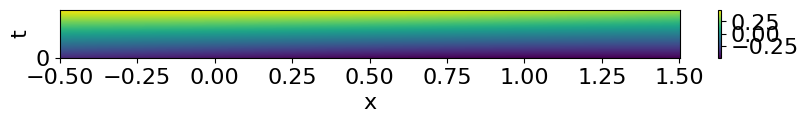

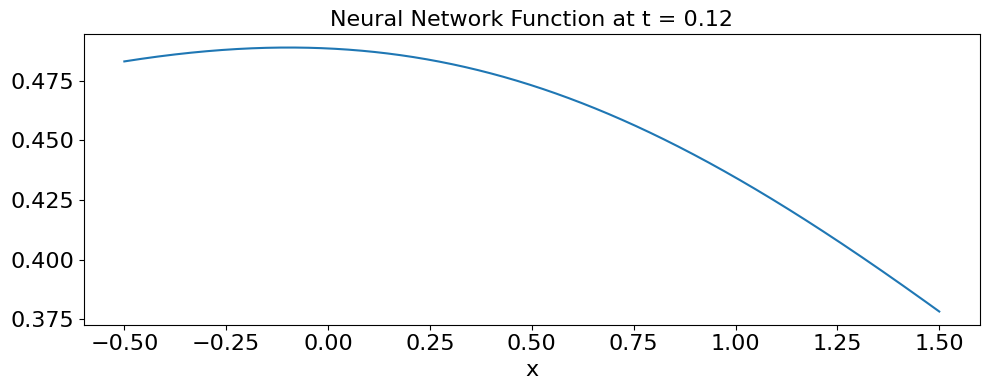

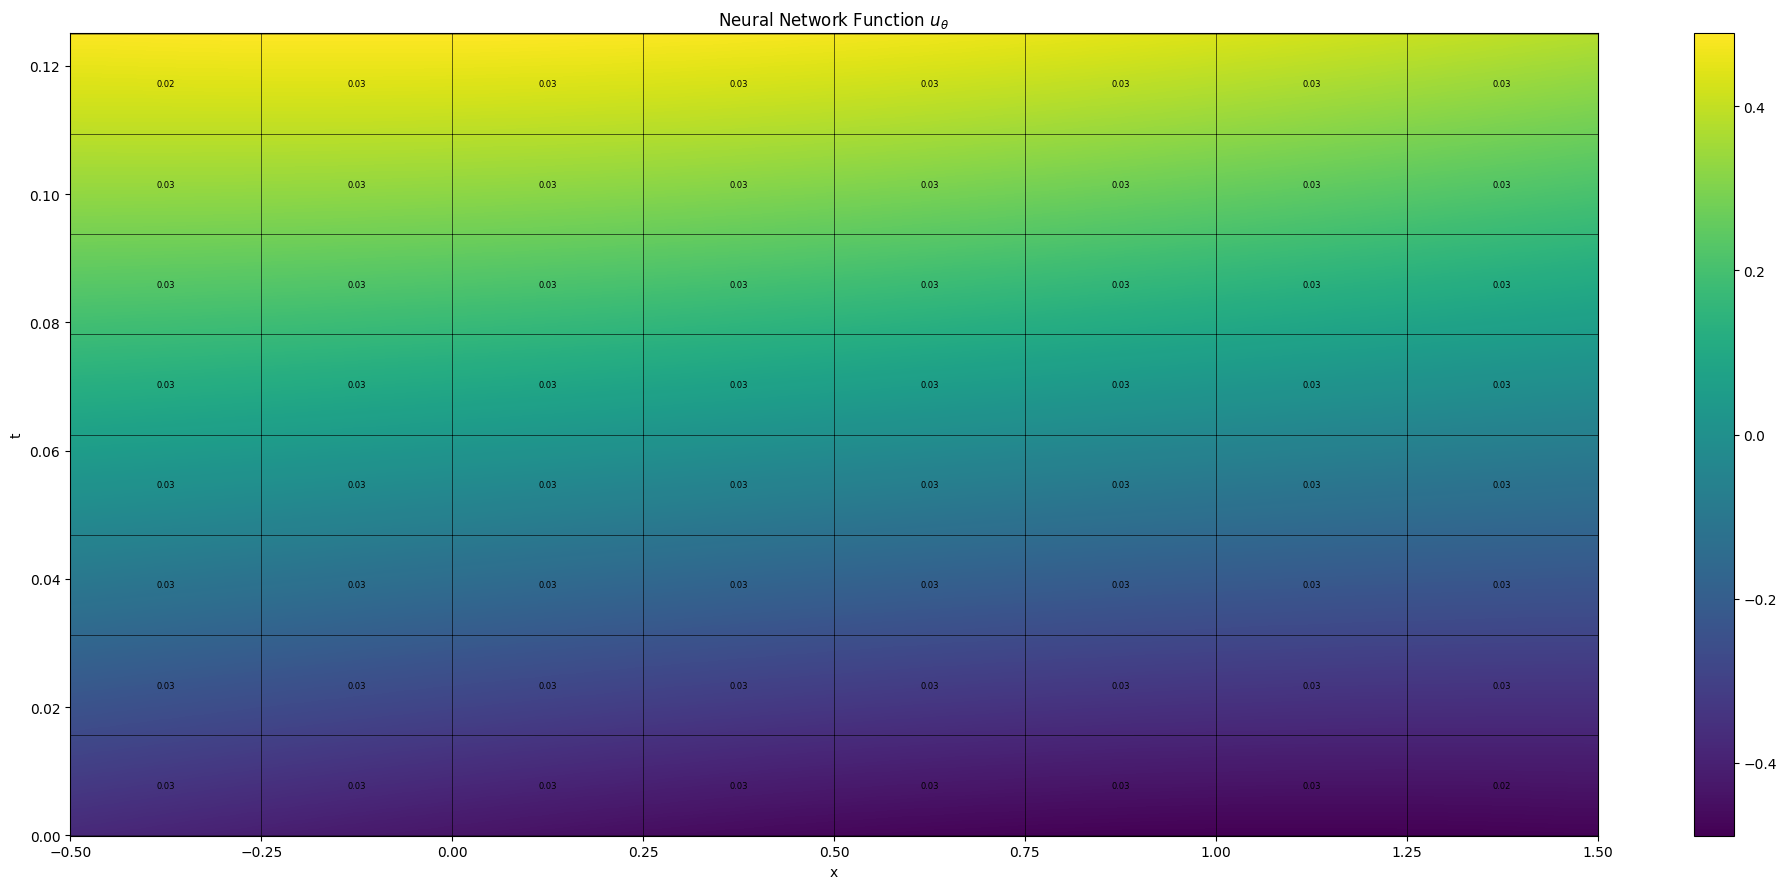

Grade 0, Iter 100, loss_eqn: 1.558912, loss_eqn_from_kh: 1.558912, loss_l1: 1.558912, loss_ibc: 1.592162
Grade 0, Iter 200, loss_eqn: 1.831057, loss_eqn_from_kh: 1.831056, loss_l1: 1.831056, loss_ibc: 0.311346
Grade 0, Iter 300, loss_eqn: 0.700260, loss_eqn_from_kh: 0.700260, loss_l1: 0.700260, loss_ibc: 0.110175
Grade 0, Iter 400, loss_eqn: 0.633372, loss_eqn_from_kh: 0.633372, loss_l1: 0.633372, loss_ibc: 0.061296
Grade 0, Iter 500, loss_eqn: 0.604203, loss_eqn_from_kh: 0.604203, loss_l1: 0.604203, loss_ibc: 0.043885
Grade 0, Iter 600, loss_eqn: 0.559857, loss_eqn_from_kh: 0.559857, loss_l1: 0.559857, loss_ibc: 0.033594
Grade 0, Iter 700, loss_eqn: 0.405517, loss_eqn_from_kh: 0.405517, loss_l1: 0.405517, loss_ibc: 0.027150
Grade 0, Iter 800, loss_eqn: 0.415548, loss_eqn_from_kh: 0.415548, loss_l1: 0.415548, loss_ibc: 0.022603
Grade 0, Iter 900, loss_eqn: 0.344783, loss_eqn_from_kh: 0.344783, loss_l1: 0.344783, loss_ibc: 0.030436
Grade 0, Iter 1000, lambda_ic: 9.658100, lambda_bc: 29.

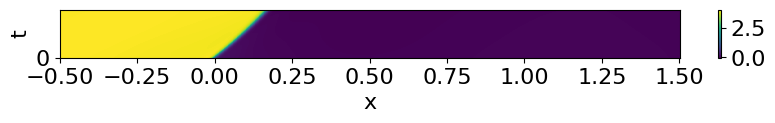

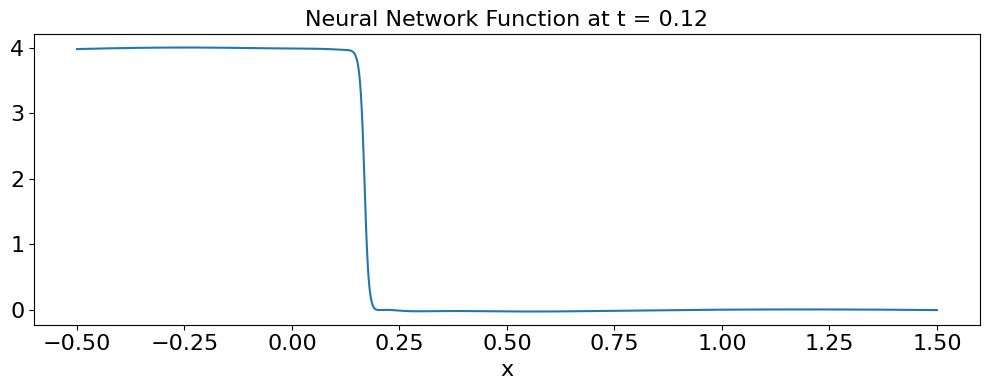

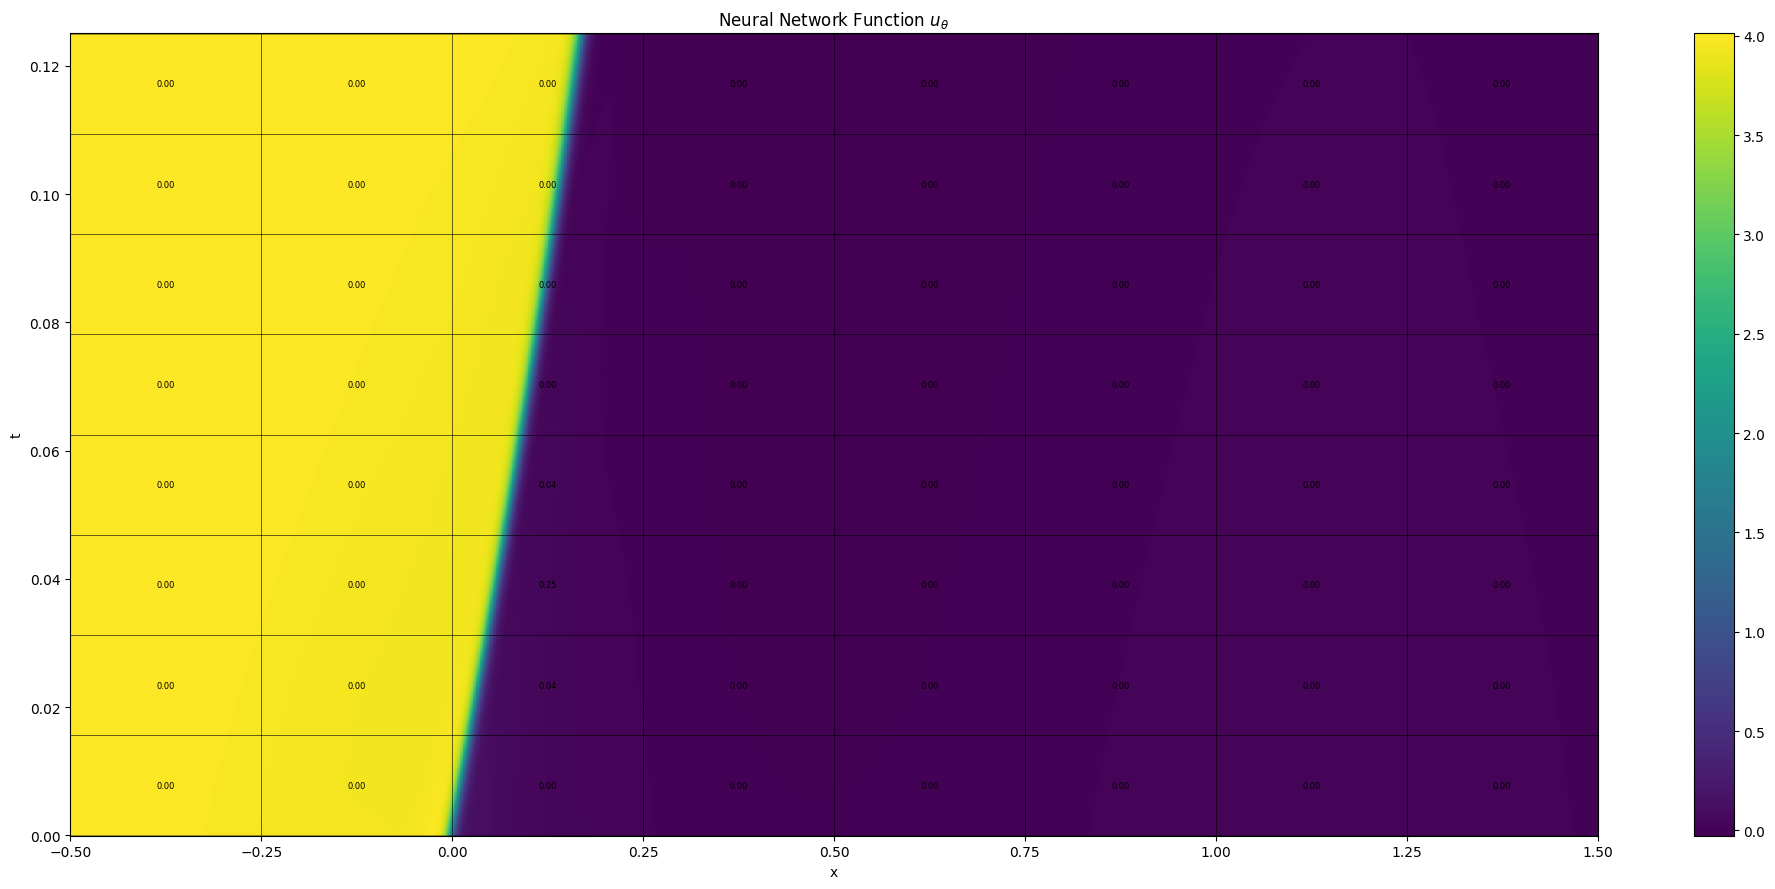

Grade 0, Iter 1100, loss_eqn: 0.414573, loss_eqn_from_kh: 0.414573, loss_l1: 0.414573, loss_ibc: 0.015738
Grade 0, Iter 1200, loss_eqn: 0.460046, loss_eqn_from_kh: 0.460046, loss_l1: 0.460670, loss_ibc: 0.018508
Grade 0, Iter 1300, loss_eqn: 0.319485, loss_eqn_from_kh: 0.319485, loss_l1: 0.319895, loss_ibc: 0.012179
Grade 0, Iter 1400, loss_eqn: 0.114835, loss_eqn_from_kh: 0.114835, loss_l1: 0.114835, loss_ibc: 0.006390
Grade 0, Iter 1500, loss_eqn: 0.039746, loss_eqn_from_kh: 0.039746, loss_l1: 0.039749, loss_ibc: 0.004653
Grade 0, Iter 1600, loss_eqn: 0.029803, loss_eqn_from_kh: 0.029803, loss_l1: 0.029803, loss_ibc: 0.007803
Grade 0, Iter 1700, loss_eqn: 0.011766, loss_eqn_from_kh: 0.011766, loss_l1: 0.011766, loss_ibc: 0.007133
Grade 0, Iter 1800, loss_eqn: 0.009991, loss_eqn_from_kh: 0.009991, loss_l1: 0.009991, loss_ibc: 0.004800
Grade 0, Iter 1900, loss_eqn: 0.010449, loss_eqn_from_kh: 0.010449, loss_l1: 0.010449, loss_ibc: 0.004101
Grade 0, Iter 2000, lambda_ic: 9.559291, lambd

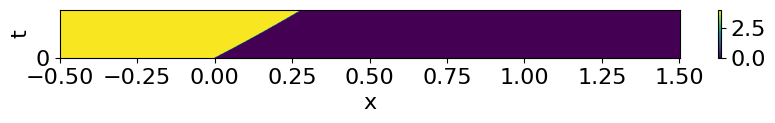

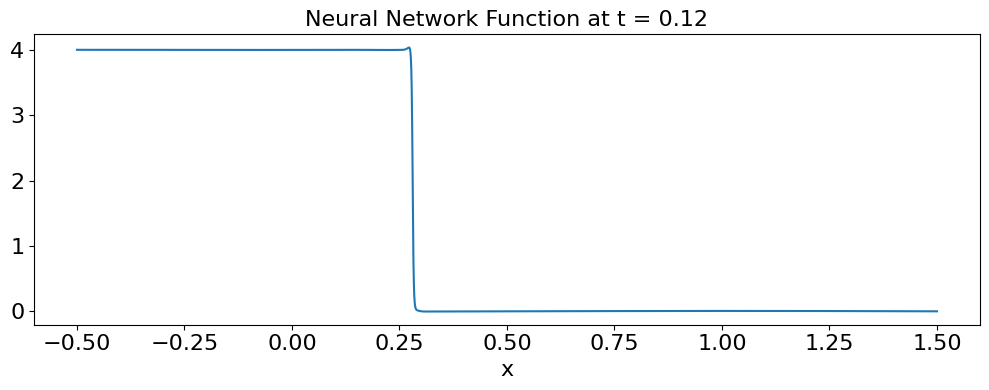

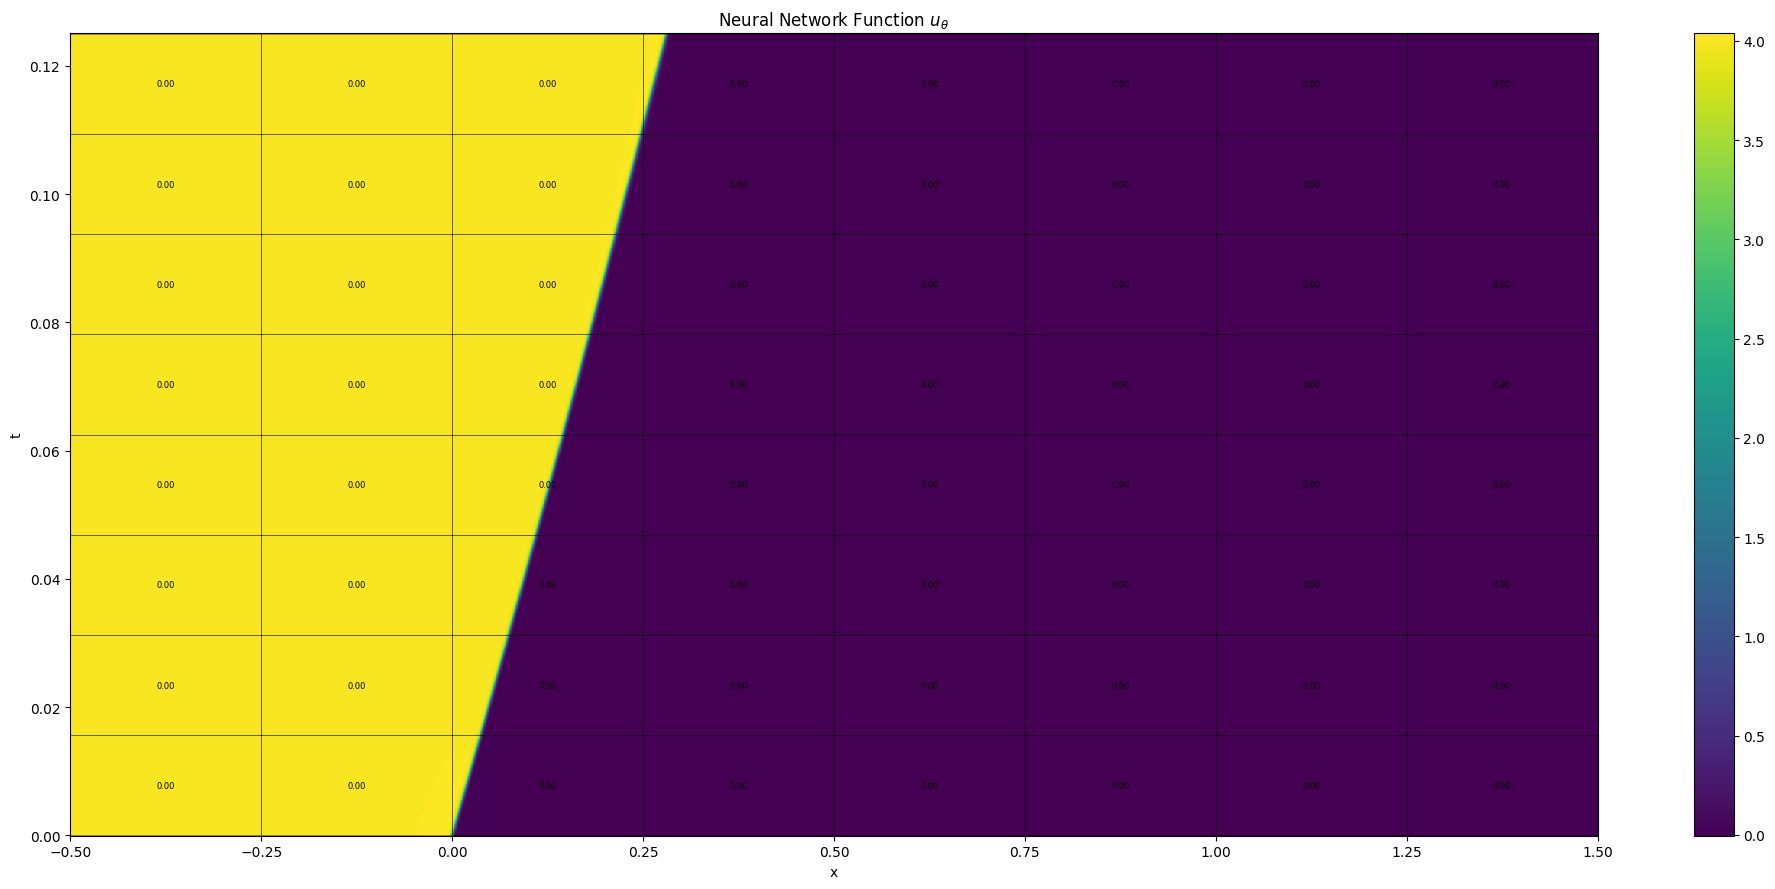

Grade 0, Iter 2100, loss_eqn: 0.009479, loss_eqn_from_kh: 0.009479, loss_l1: 0.009479, loss_ibc: 0.003533
Grade 0, Iter 2200, loss_eqn: 0.004952, loss_eqn_from_kh: 0.004952, loss_l1: 0.004974, loss_ibc: 0.004009
Grade 0, Iter 2300, loss_eqn: 0.004959, loss_eqn_from_kh: 0.004959, loss_l1: 0.004959, loss_ibc: 0.003195
Grade 0, Iter 2400, loss_eqn: 0.003855, loss_eqn_from_kh: 0.003855, loss_l1: 0.003855, loss_ibc: 0.004398
Grade 0, Iter 2500, loss_eqn: 0.003780, loss_eqn_from_kh: 0.003780, loss_l1: 0.003780, loss_ibc: 0.003005
Grade 0, Iter 2600, loss_eqn: 0.002020, loss_eqn_from_kh: 0.002020, loss_l1: 0.002020, loss_ibc: 0.003141
Grade 0, Iter 2700, loss_eqn: 0.002818, loss_eqn_from_kh: 0.002818, loss_l1: 0.002818, loss_ibc: 0.002853
Grade 0, Iter 2800, loss_eqn: 0.002287, loss_eqn_from_kh: 0.002287, loss_l1: 0.002287, loss_ibc: 0.003158
Grade 0, Iter 2900, loss_eqn: 0.002120, loss_eqn_from_kh: 0.002120, loss_l1: 0.002120, loss_ibc: 0.002770
Grade 0, Iter 3000, lambda_ic: 8.923653, lambd

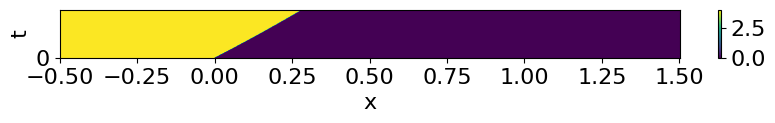

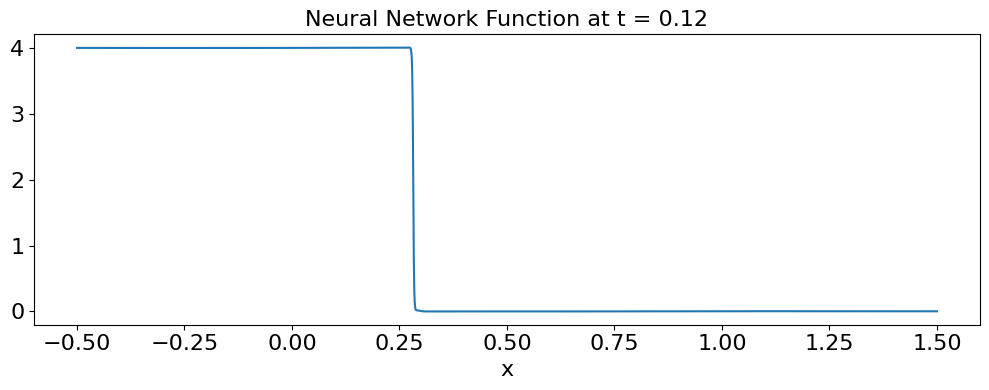

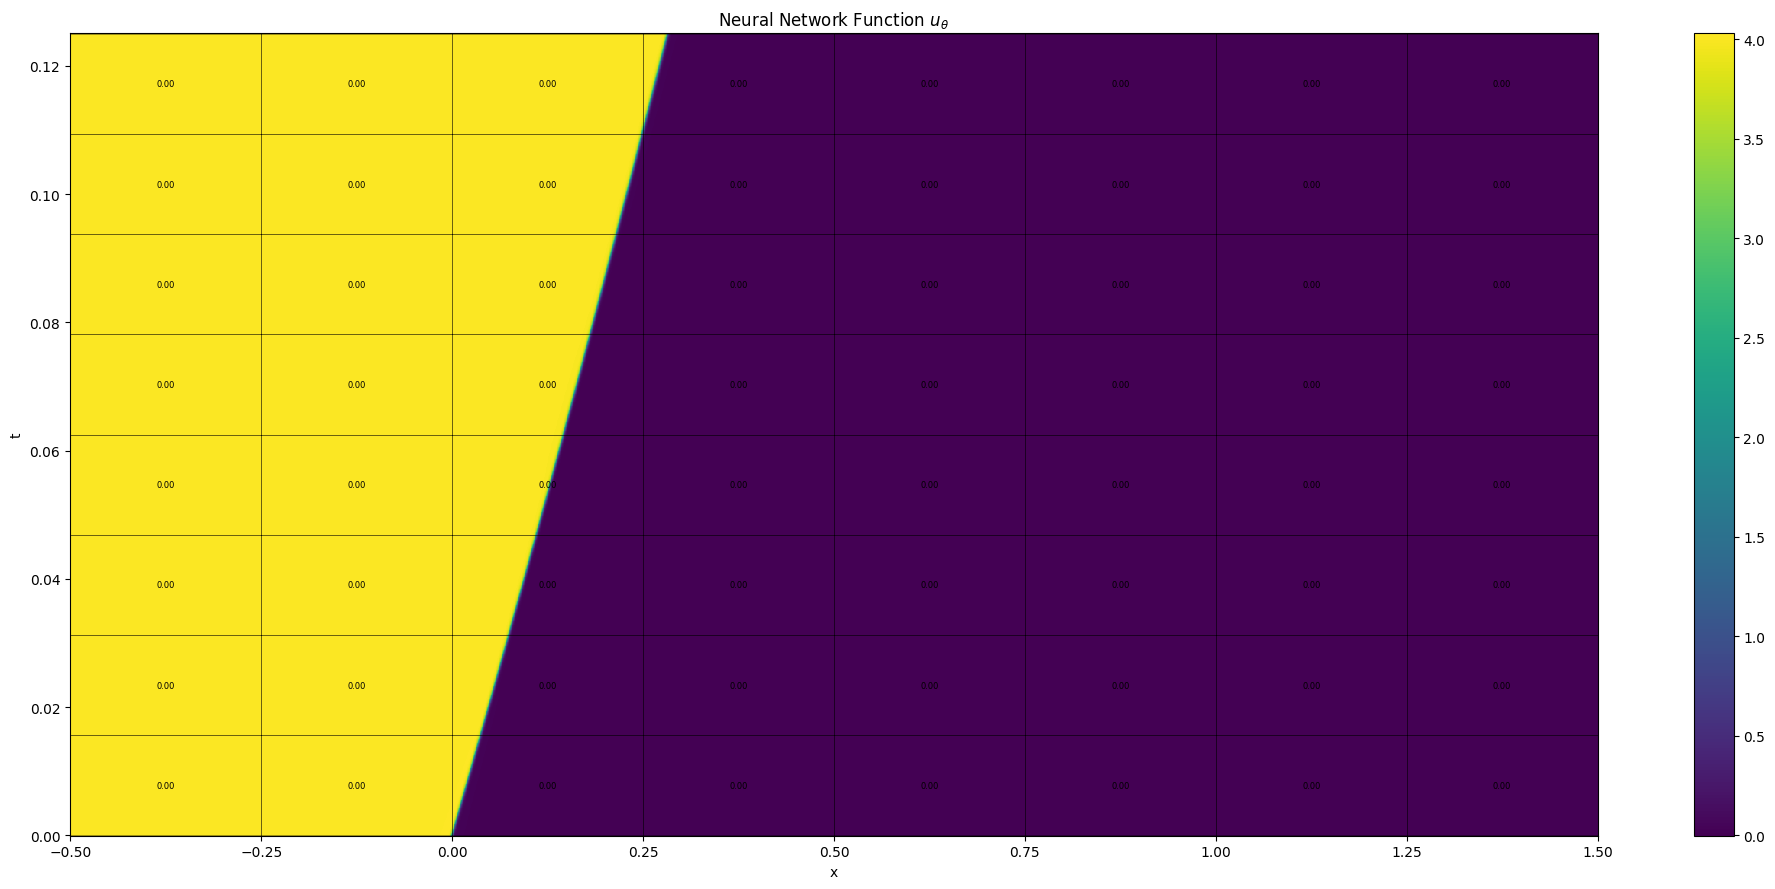

Grade 0, Iter 3100, loss_eqn: 0.003022, loss_eqn_from_kh: 0.003022, loss_l1: 0.003022, loss_ibc: 0.002604
Grade 0, Iter 3200, loss_eqn: 0.002866, loss_eqn_from_kh: 0.002866, loss_l1: 0.002866, loss_ibc: 0.002564
Grade 0, Iter 3300, loss_eqn: 0.001625, loss_eqn_from_kh: 0.001625, loss_l1: 0.001625, loss_ibc: 0.002509
Grade 0, Iter 3400, loss_eqn: 0.002114, loss_eqn_from_kh: 0.002114, loss_l1: 0.002114, loss_ibc: 0.002471
Grade 0, Iter 3500, loss_eqn: 0.002876, loss_eqn_from_kh: 0.002876, loss_l1: 0.002876, loss_ibc: 0.002430
Grade 0, Iter 3600, loss_eqn: 0.002949, loss_eqn_from_kh: 0.002949, loss_l1: 0.002949, loss_ibc: 0.002395
Grade 0, Iter 3700, loss_eqn: 0.001023, loss_eqn_from_kh: 0.001023, loss_l1: 0.001023, loss_ibc: 0.002364
Grade 0, Iter 3800, loss_eqn: 0.001355, loss_eqn_from_kh: 0.001355, loss_l1: 0.001355, loss_ibc: 0.002334
Grade 0, Iter 3900, loss_eqn: 0.001763, loss_eqn_from_kh: 0.001763, loss_l1: 0.001763, loss_ibc: 0.002312
Grade 0, Iter 4000, lambda_ic: 11.275303, lamb

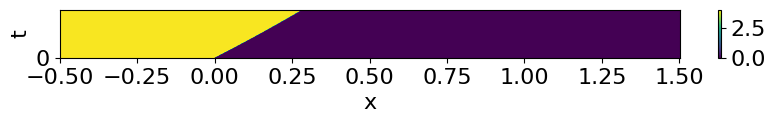

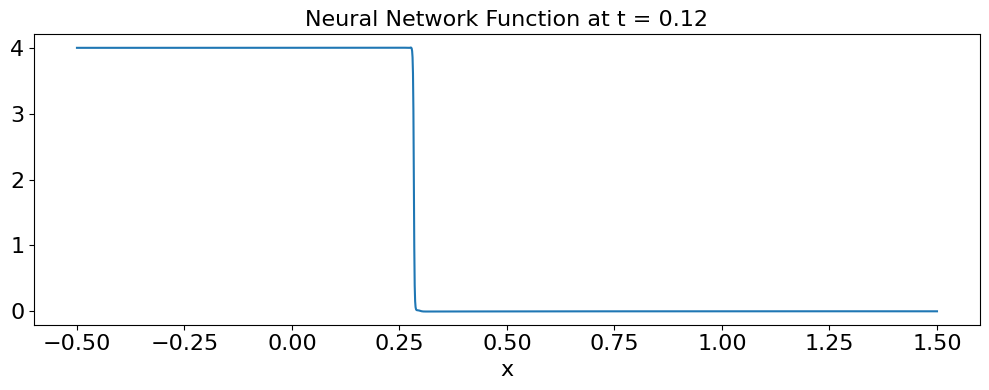

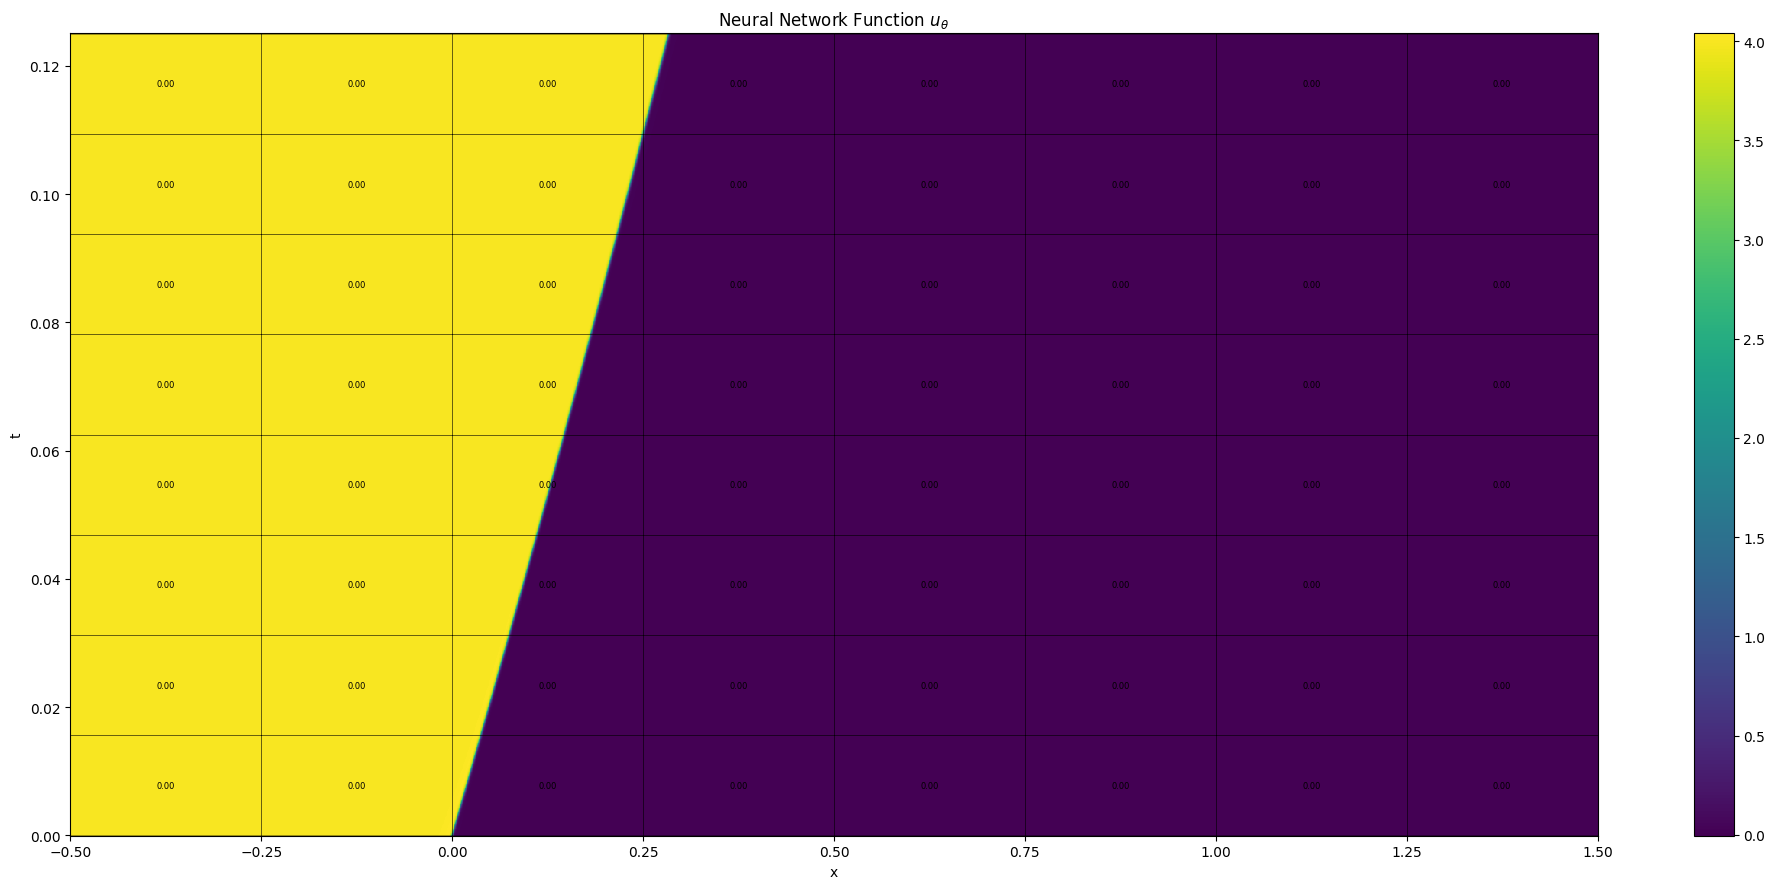

Grade 0, Iter 4100, loss_eqn: 0.001732, loss_eqn_from_kh: 0.001732, loss_l1: 0.001732, loss_ibc: 0.002266
Grade 0, Iter 4200, loss_eqn: 0.000975, loss_eqn_from_kh: 0.000975, loss_l1: 0.000975, loss_ibc: 0.002244
Grade 0, Iter 4300, loss_eqn: 0.001109, loss_eqn_from_kh: 0.001109, loss_l1: 0.001109, loss_ibc: 0.002228
Grade 0, Iter 4400, loss_eqn: 0.000652, loss_eqn_from_kh: 0.000652, loss_l1: 0.000652, loss_ibc: 0.002214
Grade 0, Iter 4500, loss_eqn: 0.000757, loss_eqn_from_kh: 0.000757, loss_l1: 0.000757, loss_ibc: 0.002203
Grade 0, Iter 4600, loss_eqn: 0.000910, loss_eqn_from_kh: 0.000910, loss_l1: 0.000910, loss_ibc: 0.002194
Grade 0, Iter 4700, loss_eqn: 0.000544, loss_eqn_from_kh: 0.000544, loss_l1: 0.000544, loss_ibc: 0.002188
Grade 0, Iter 4800, loss_eqn: 0.000517, loss_eqn_from_kh: 0.000517, loss_l1: 0.000517, loss_ibc: 0.002183
Grade 0, Iter 4900, loss_eqn: 0.000531, loss_eqn_from_kh: 0.000531, loss_l1: 0.000531, loss_ibc: 0.002178
Train time for stage1: 430.644247 seconds

Plo

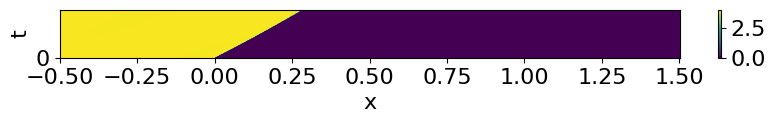

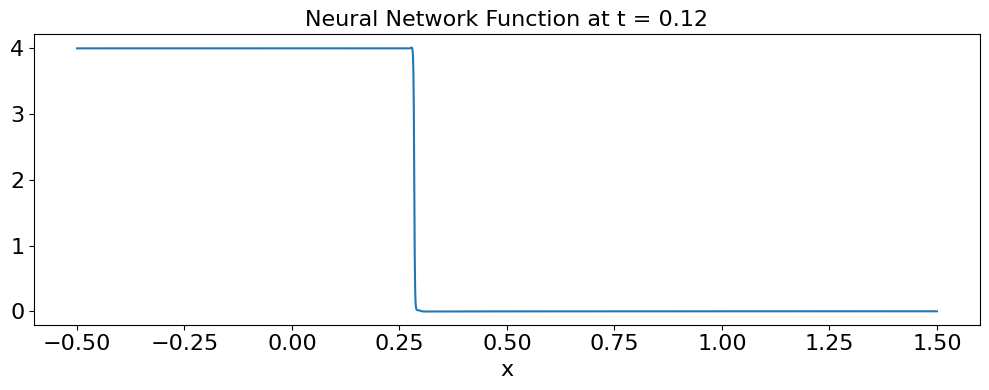

Adding grade 1 with hidden dims [64, 64, 64, 64, 64]
Partition type: rect, dg_type: Q1, p_dof: 4

Training segment [0.1250, 0.2500]
Skipping pre-training as pre_epochs is set to 0.

Starting Train Stage with MGDL

Stage 1: Sequential Grade Training

Training Grade 0
The largest W^{1,inf} norm of k_h coeffs is 4.771857
Grade 0, Iter 0, lambda_ic: 9.240287, lambda_bc: 9.637137, lambda_eqn: 1.134259
Grade 0, Iter 0, loss_eqn: 1.832506, loss_eqn_from_kh: 1.832505, loss_l1: 1.832505, loss_ibc: 23.441591


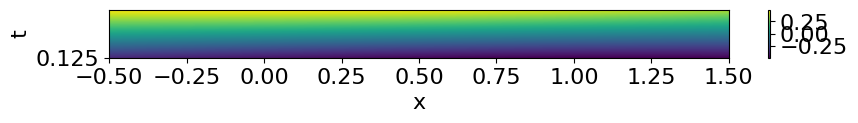

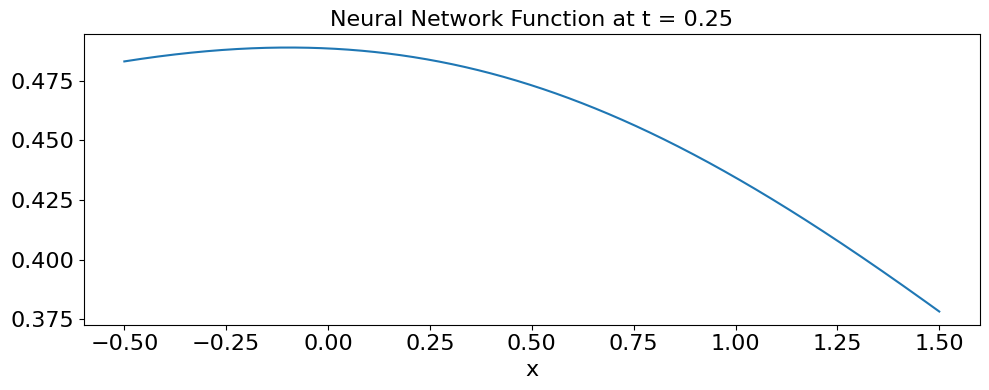

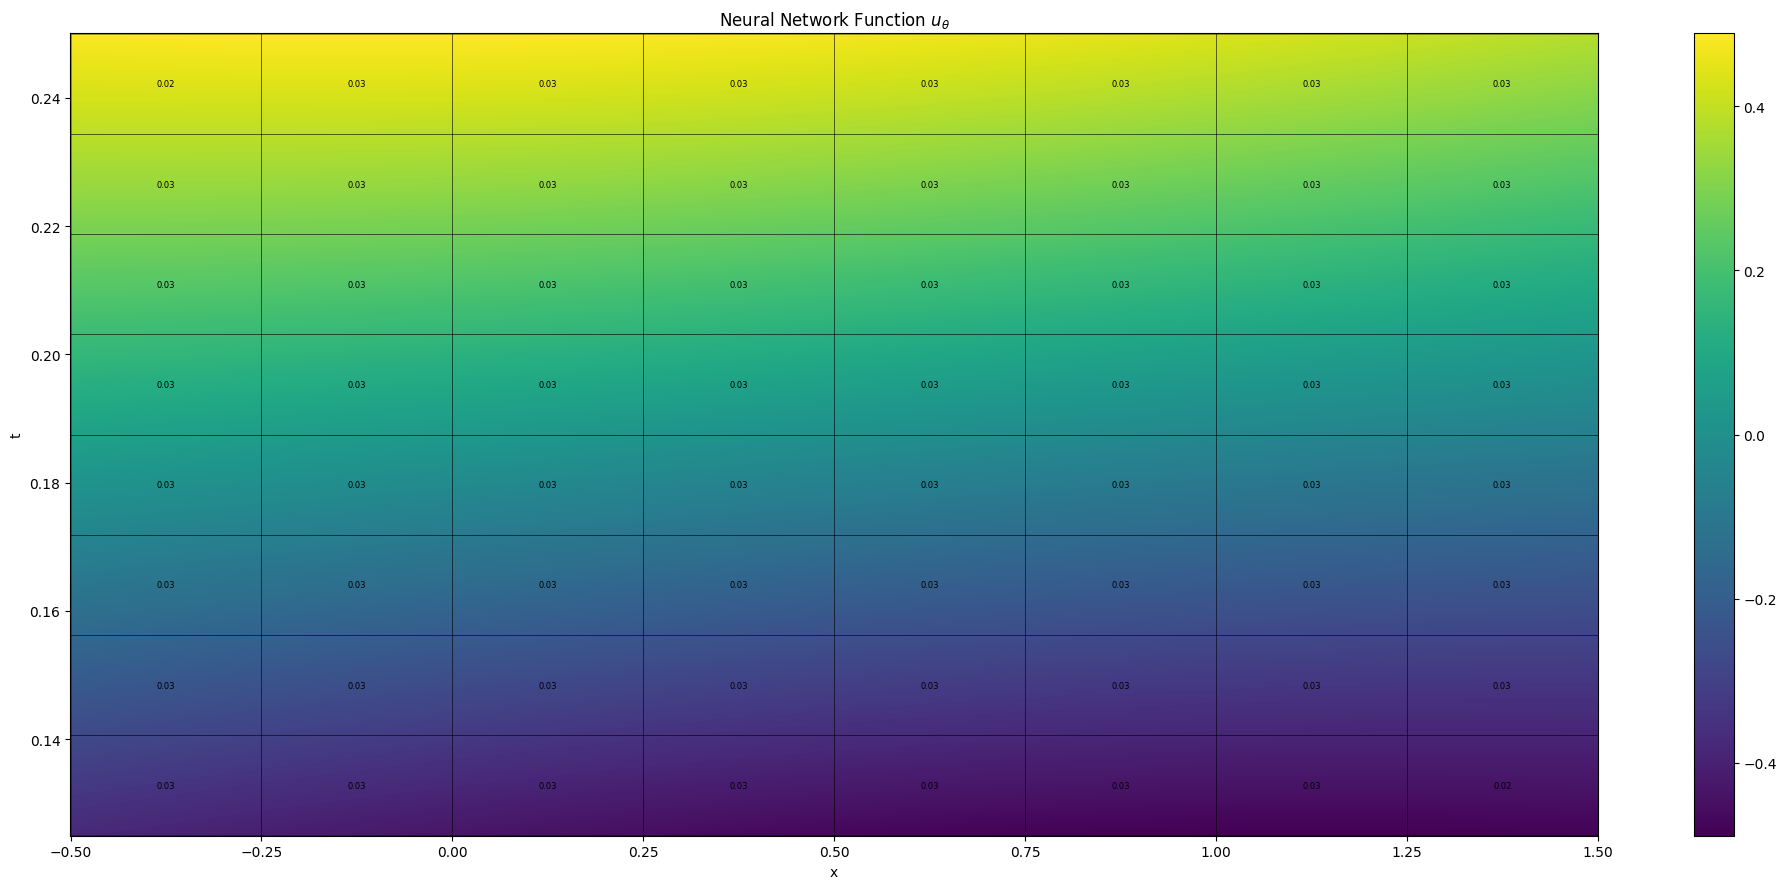

Grade 0, Iter 100, loss_eqn: 0.757186, loss_eqn_from_kh: 0.757186, loss_l1: 0.757186, loss_ibc: 1.343928
Grade 0, Iter 200, loss_eqn: 1.543741, loss_eqn_from_kh: 1.543741, loss_l1: 1.543741, loss_ibc: 0.949844
Grade 0, Iter 300, loss_eqn: 0.722187, loss_eqn_from_kh: 0.722187, loss_l1: 0.722187, loss_ibc: 0.173956
Grade 0, Iter 400, loss_eqn: 0.581978, loss_eqn_from_kh: 0.581978, loss_l1: 0.581978, loss_ibc: 0.070792
Grade 0, Iter 500, loss_eqn: 0.549264, loss_eqn_from_kh: 0.549264, loss_l1: 0.549264, loss_ibc: 0.052703
Grade 0, Iter 600, loss_eqn: 0.513160, loss_eqn_from_kh: 0.513160, loss_l1: 0.513160, loss_ibc: 0.031685
Grade 0, Iter 700, loss_eqn: 0.537941, loss_eqn_from_kh: 0.537941, loss_l1: 0.537941, loss_ibc: 0.024052
Grade 0, Iter 800, loss_eqn: 0.439896, loss_eqn_from_kh: 0.439896, loss_l1: 0.439896, loss_ibc: 0.020278
Grade 0, Iter 900, loss_eqn: 0.288297, loss_eqn_from_kh: 0.288297, loss_l1: 0.288297, loss_ibc: 0.028943
Grade 0, Iter 1000, lambda_ic: 19.758137, lambda_bc: 11

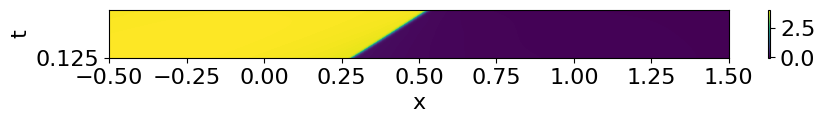

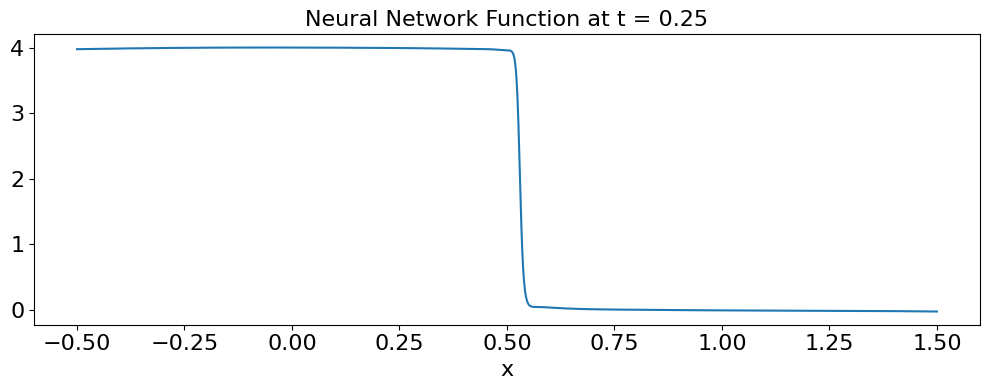

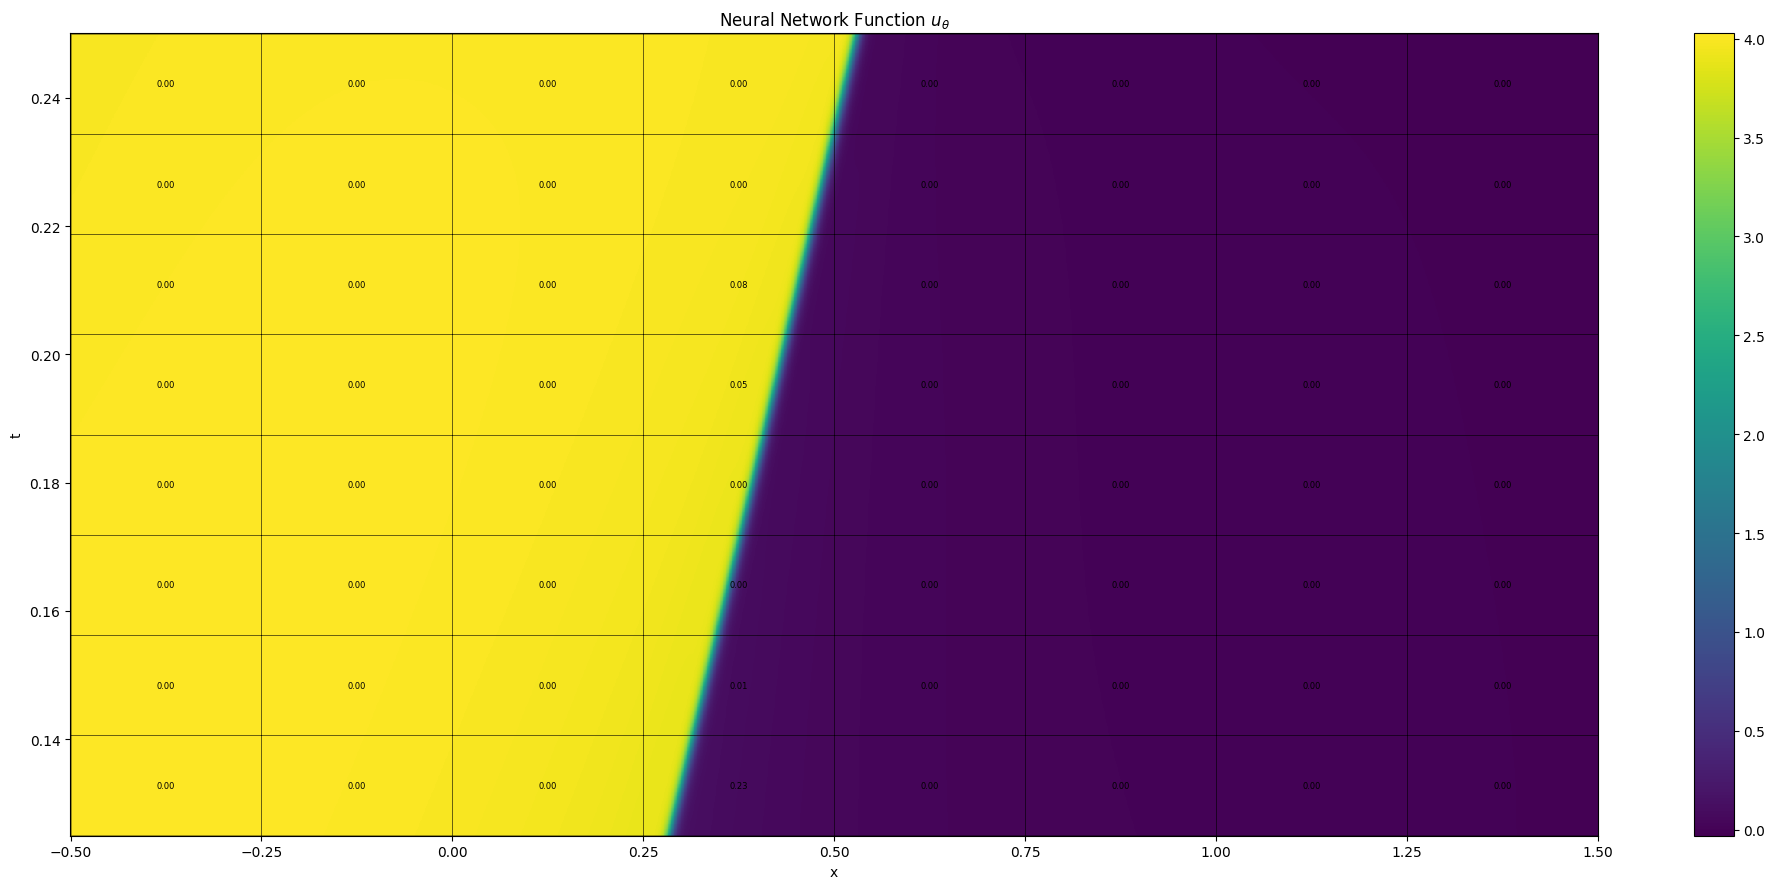

Grade 0, Iter 1100, loss_eqn: 0.285231, loss_eqn_from_kh: 0.285231, loss_l1: 0.285533, loss_ibc: 0.005215
Grade 0, Iter 1200, loss_eqn: 0.203487, loss_eqn_from_kh: 0.203487, loss_l1: 0.203603, loss_ibc: 0.001863
Grade 0, Iter 1300, loss_eqn: 0.035500, loss_eqn_from_kh: 0.035500, loss_l1: 0.035500, loss_ibc: 0.000279
Grade 0, Iter 1400, loss_eqn: 0.026892, loss_eqn_from_kh: 0.026892, loss_l1: 0.026892, loss_ibc: 0.000353
Grade 0, Iter 1500, loss_eqn: 0.016307, loss_eqn_from_kh: 0.016307, loss_l1: 0.016307, loss_ibc: 0.000622
Grade 0, Iter 1600, loss_eqn: 0.038295, loss_eqn_from_kh: 0.038295, loss_l1: 0.038295, loss_ibc: 0.000697
Grade 0, Iter 1700, loss_eqn: 0.012204, loss_eqn_from_kh: 0.012204, loss_l1: 0.012204, loss_ibc: 0.000141
Grade 0, Iter 1800, loss_eqn: 0.025362, loss_eqn_from_kh: 0.025362, loss_l1: 0.025362, loss_ibc: 0.000716
Grade 0, Iter 1900, loss_eqn: 0.025528, loss_eqn_from_kh: 0.025528, loss_l1: 0.025528, loss_ibc: 0.000251
Grade 0, Iter 2000, lambda_ic: 32.545902, lamb

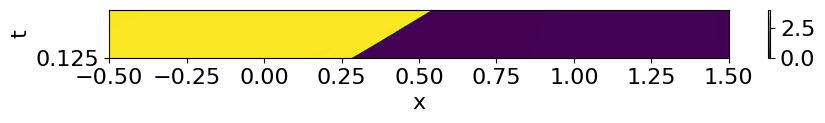

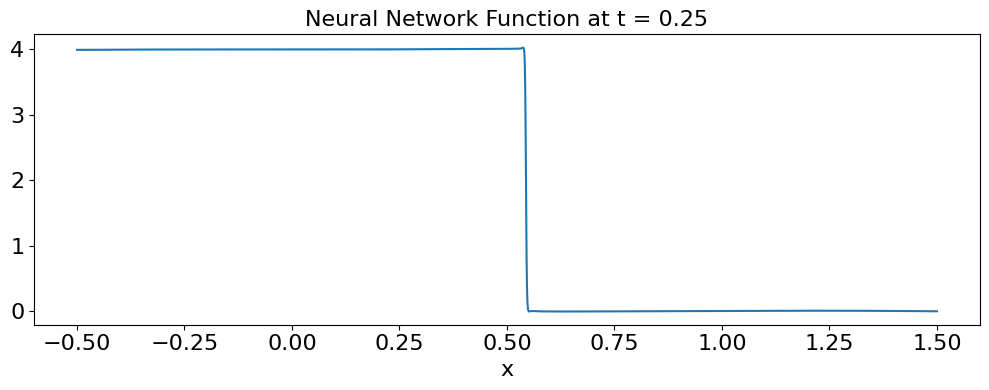

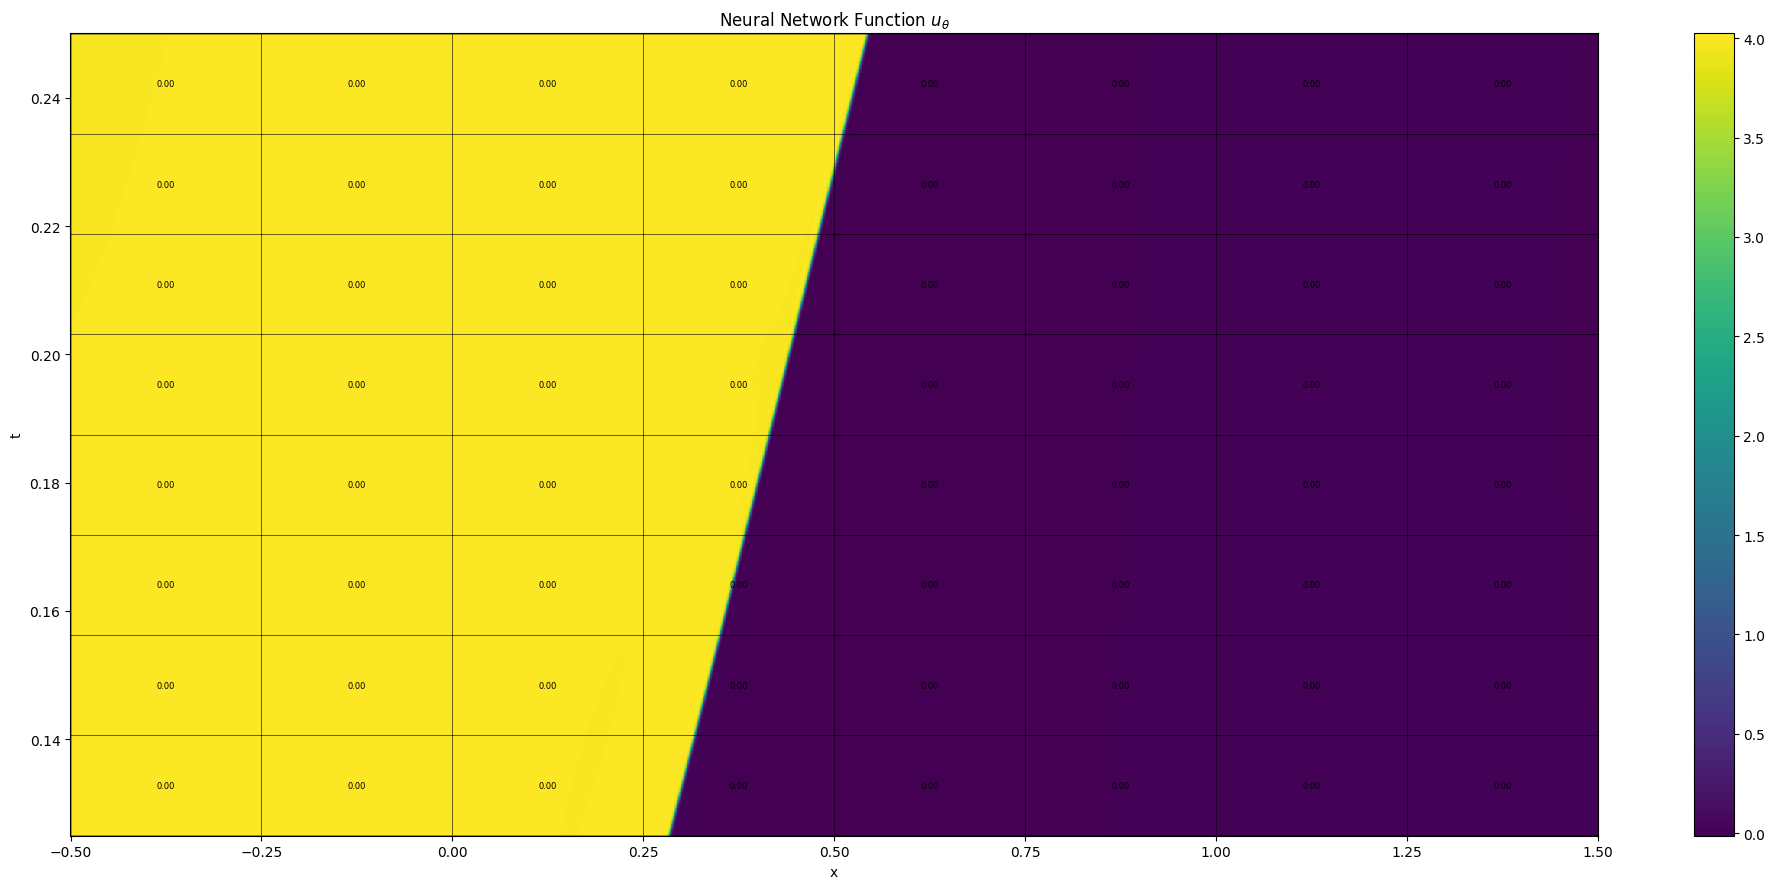

Grade 0, Iter 2100, loss_eqn: 0.013884, loss_eqn_from_kh: 0.013884, loss_l1: 0.013884, loss_ibc: 0.000137
Grade 0, Iter 2200, loss_eqn: 0.022918, loss_eqn_from_kh: 0.022918, loss_l1: 0.022918, loss_ibc: 0.000238
Grade 0, Iter 2300, loss_eqn: 0.020013, loss_eqn_from_kh: 0.020013, loss_l1: 0.020013, loss_ibc: 0.000262
Grade 0, Iter 2400, loss_eqn: 0.017903, loss_eqn_from_kh: 0.017903, loss_l1: 0.017903, loss_ibc: 0.000072
Grade 0, Iter 2500, loss_eqn: 0.013193, loss_eqn_from_kh: 0.013193, loss_l1: 0.013193, loss_ibc: 0.000120
Grade 0, Iter 2600, loss_eqn: 0.007179, loss_eqn_from_kh: 0.007179, loss_l1: 0.007179, loss_ibc: 0.000026
Grade 0, Iter 2700, loss_eqn: 0.005506, loss_eqn_from_kh: 0.005506, loss_l1: 0.005506, loss_ibc: 0.000120
Grade 0, Iter 2800, loss_eqn: 0.010969, loss_eqn_from_kh: 0.010969, loss_l1: 0.010969, loss_ibc: 0.000052
Grade 0, Iter 2900, loss_eqn: 0.008105, loss_eqn_from_kh: 0.008105, loss_l1: 0.008105, loss_ibc: 0.000023
Grade 0, Iter 3000, lambda_ic: 45.488220, lamb

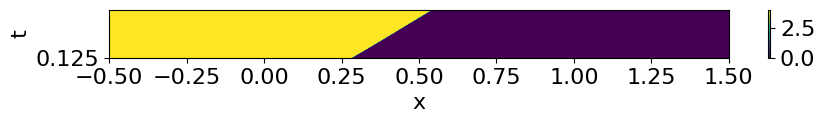

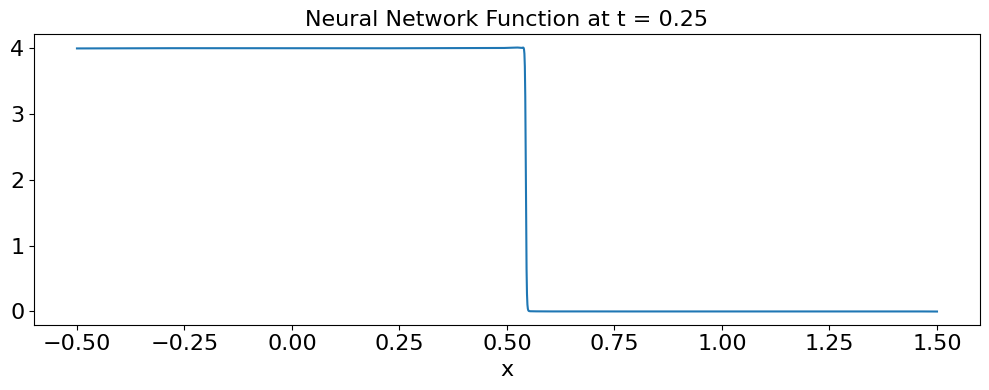

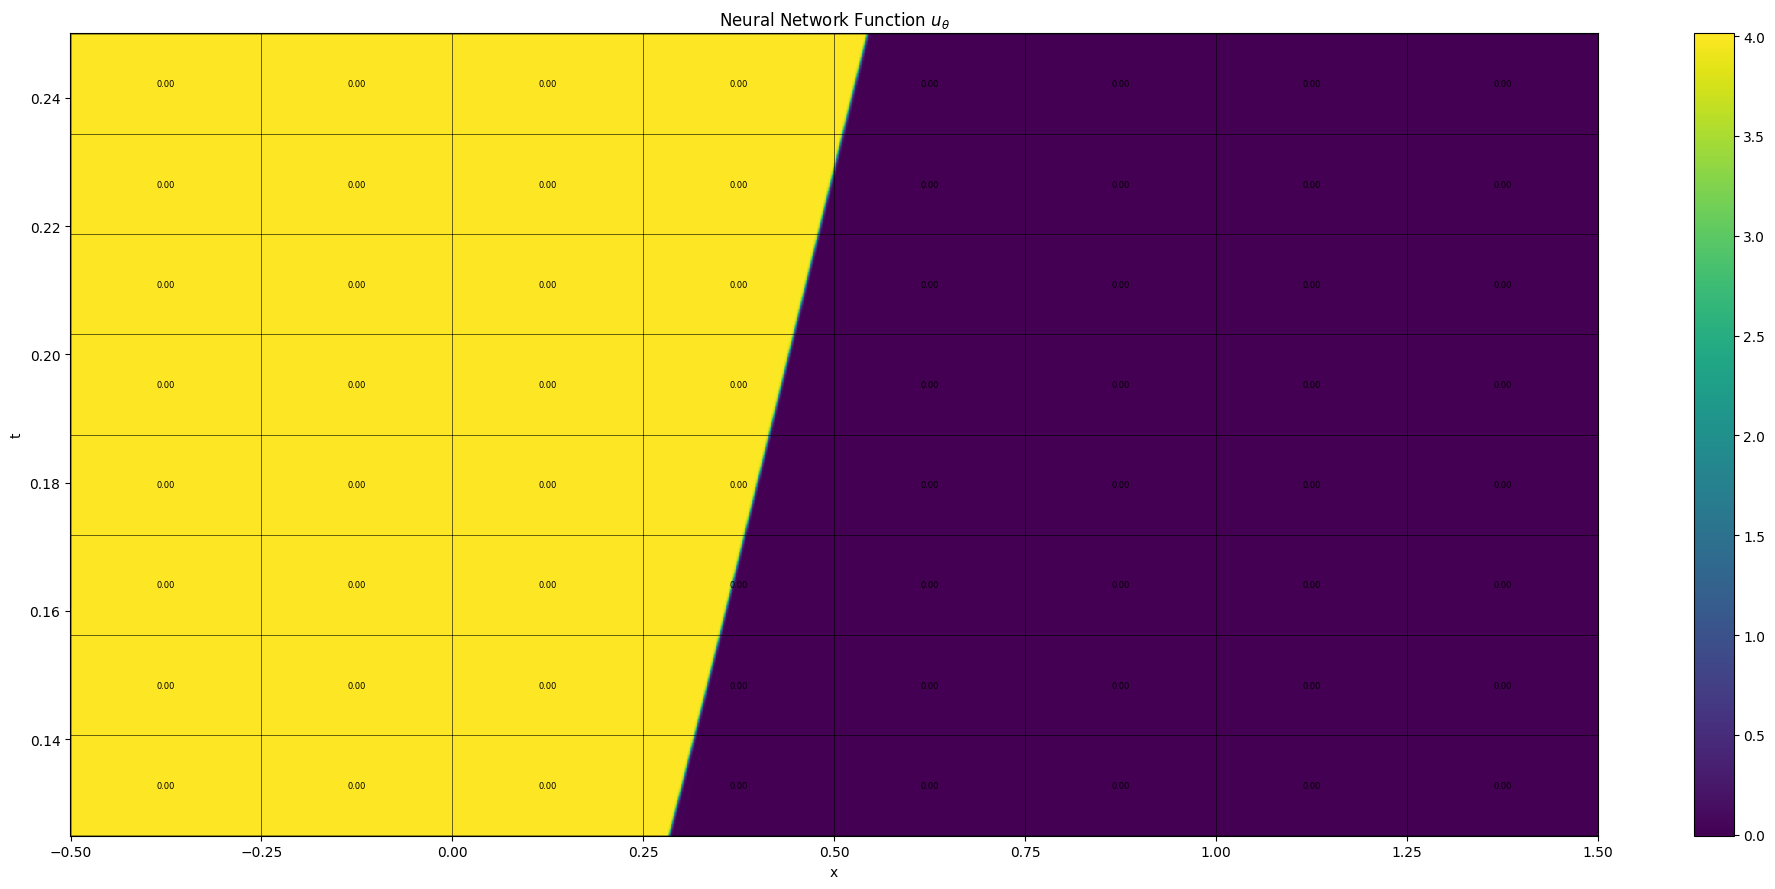

Grade 0, Iter 3100, loss_eqn: 0.011428, loss_eqn_from_kh: 0.011428, loss_l1: 0.011428, loss_ibc: 0.000099
Grade 0, Iter 3200, loss_eqn: 0.006138, loss_eqn_from_kh: 0.006138, loss_l1: 0.006138, loss_ibc: 0.000028
Grade 0, Iter 3300, loss_eqn: 0.005552, loss_eqn_from_kh: 0.005552, loss_l1: 0.005552, loss_ibc: 0.000026
Grade 0, Iter 3400, loss_eqn: 0.005831, loss_eqn_from_kh: 0.005831, loss_l1: 0.005842, loss_ibc: 0.000068
Grade 0, Iter 3500, loss_eqn: 0.004981, loss_eqn_from_kh: 0.004981, loss_l1: 0.004981, loss_ibc: 0.000006
Grade 0, Iter 3600, loss_eqn: 0.002750, loss_eqn_from_kh: 0.002750, loss_l1: 0.002750, loss_ibc: 0.000017
Grade 0, Iter 3700, loss_eqn: 0.003326, loss_eqn_from_kh: 0.003326, loss_l1: 0.003326, loss_ibc: 0.000014
Grade 0, Iter 3800, loss_eqn: 0.002234, loss_eqn_from_kh: 0.002234, loss_l1: 0.002234, loss_ibc: 0.000007
Grade 0, Iter 3900, loss_eqn: 0.002764, loss_eqn_from_kh: 0.002764, loss_l1: 0.002764, loss_ibc: 0.000005
Grade 0, Iter 4000, lambda_ic: 51.094814, lamb

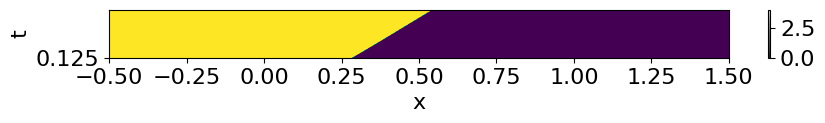

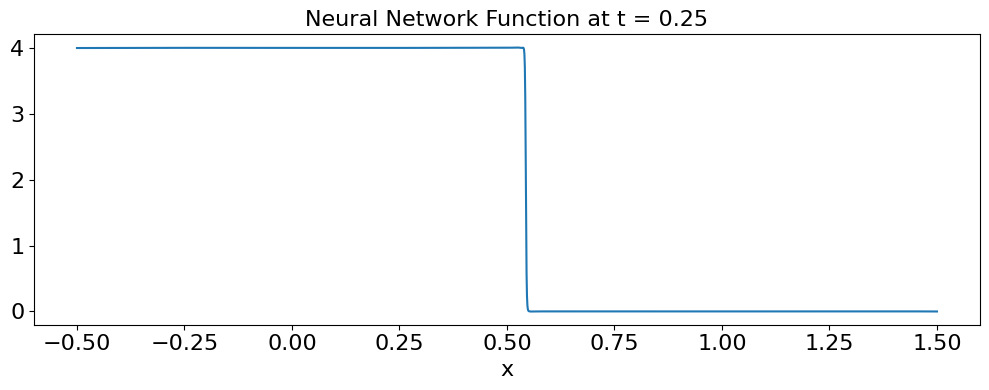

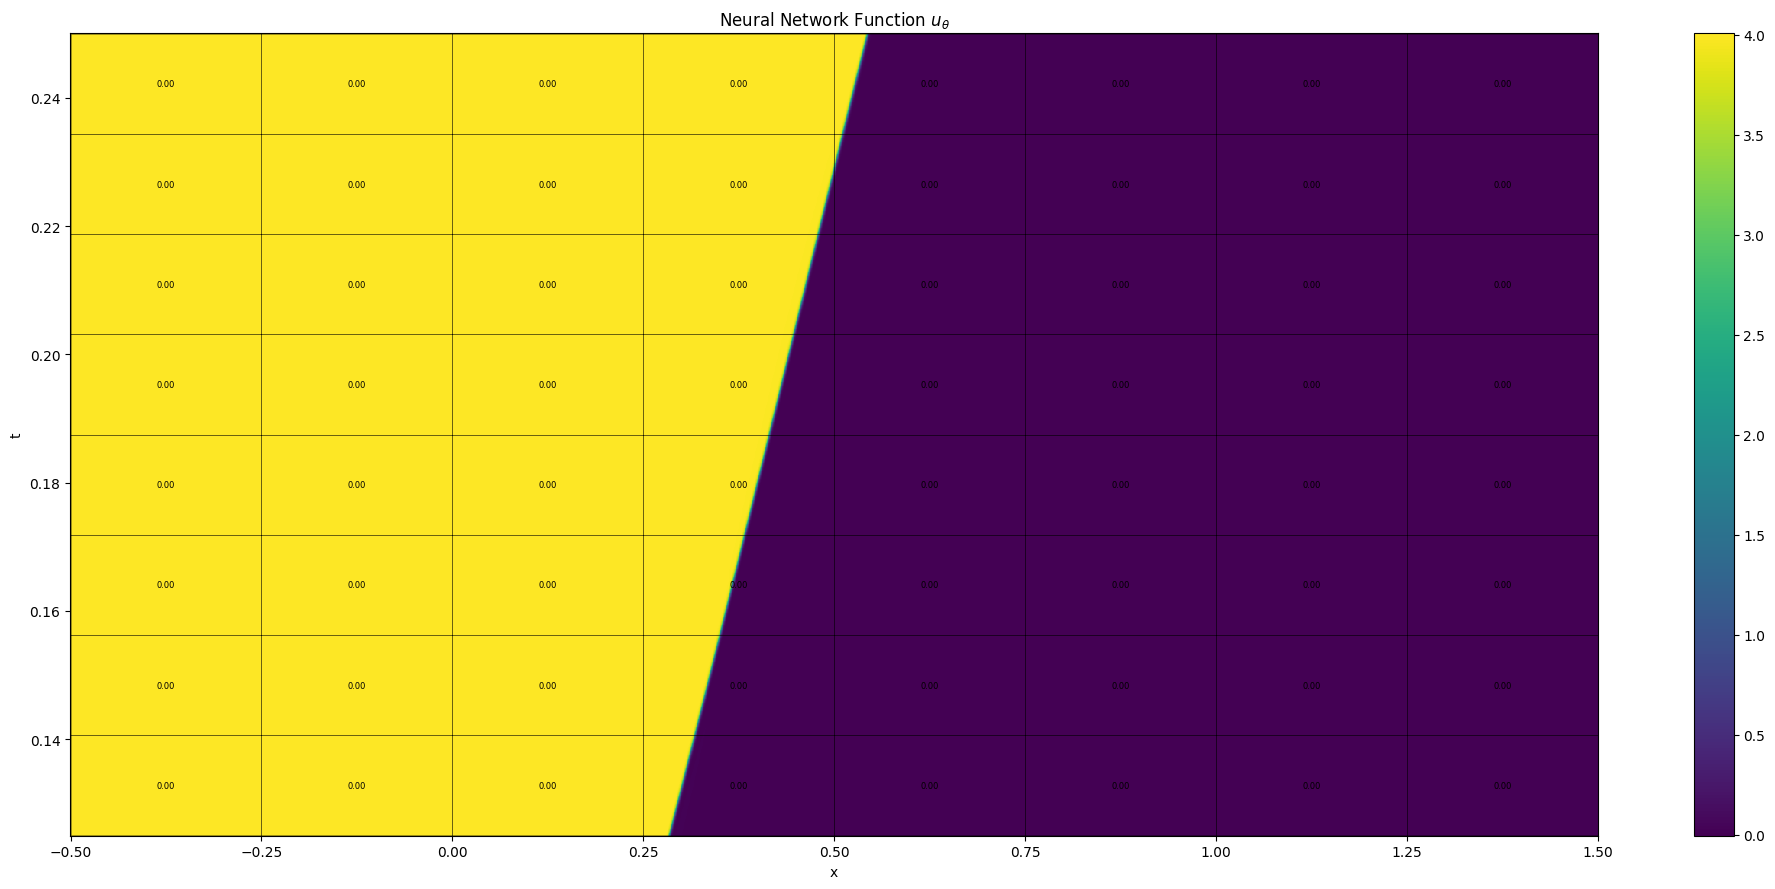

Grade 0, Iter 4100, loss_eqn: 0.001913, loss_eqn_from_kh: 0.001913, loss_l1: 0.001913, loss_ibc: 0.000004
Grade 0, Iter 4200, loss_eqn: 0.002097, loss_eqn_from_kh: 0.002097, loss_l1: 0.002097, loss_ibc: 0.000008
Grade 0, Iter 4300, loss_eqn: 0.001493, loss_eqn_from_kh: 0.001493, loss_l1: 0.001493, loss_ibc: 0.000005
Grade 0, Iter 4400, loss_eqn: 0.001527, loss_eqn_from_kh: 0.001527, loss_l1: 0.001527, loss_ibc: 0.000008
Grade 0, Iter 4500, loss_eqn: 0.001450, loss_eqn_from_kh: 0.001450, loss_l1: 0.001450, loss_ibc: 0.000004
Grade 0, Iter 4600, loss_eqn: 0.001348, loss_eqn_from_kh: 0.001348, loss_l1: 0.001350, loss_ibc: 0.000005
Grade 0, Iter 4700, loss_eqn: 0.001384, loss_eqn_from_kh: 0.001384, loss_l1: 0.001384, loss_ibc: 0.000004
Grade 0, Iter 4800, loss_eqn: 0.001265, loss_eqn_from_kh: 0.001265, loss_l1: 0.001265, loss_ibc: 0.000004
Grade 0, Iter 4900, loss_eqn: 0.001285, loss_eqn_from_kh: 0.001285, loss_l1: 0.001285, loss_ibc: 0.000004
Train time for stage1: 411.305869 seconds

Plo

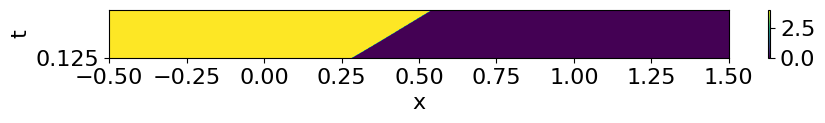

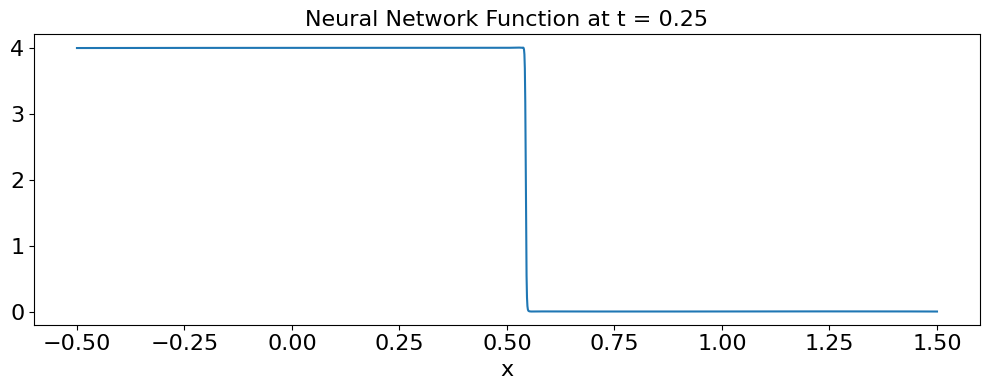

Adding grade 1 with hidden dims [64, 64, 64, 64, 64]
Partition type: rect, dg_type: Q1, p_dof: 4

Training segment [0.2500, 0.3750]
Skipping pre-training as pre_epochs is set to 0.

Starting Train Stage with MGDL

Stage 1: Sequential Grade Training

Training Grade 0
The largest W^{1,inf} norm of k_h coeffs is 4.771857
Grade 0, Iter 0, lambda_ic: 9.209434, lambda_bc: 9.711896, lambda_eqn: 1.161745
Grade 0, Iter 0, loss_eqn: 1.832439, loss_eqn_from_kh: 1.832439, loss_l1: 1.832439, loss_ibc: 26.001099


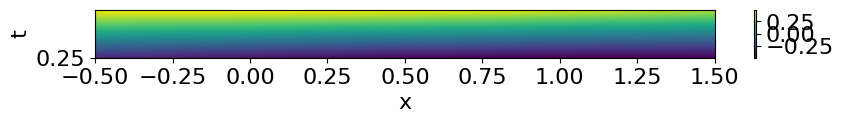

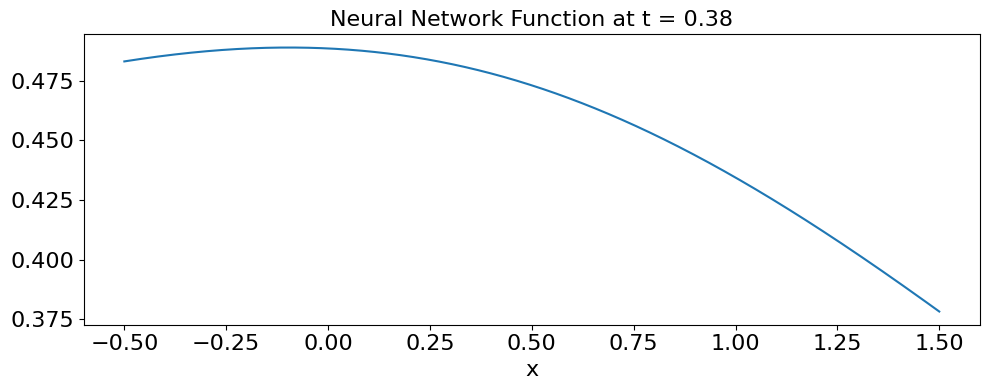

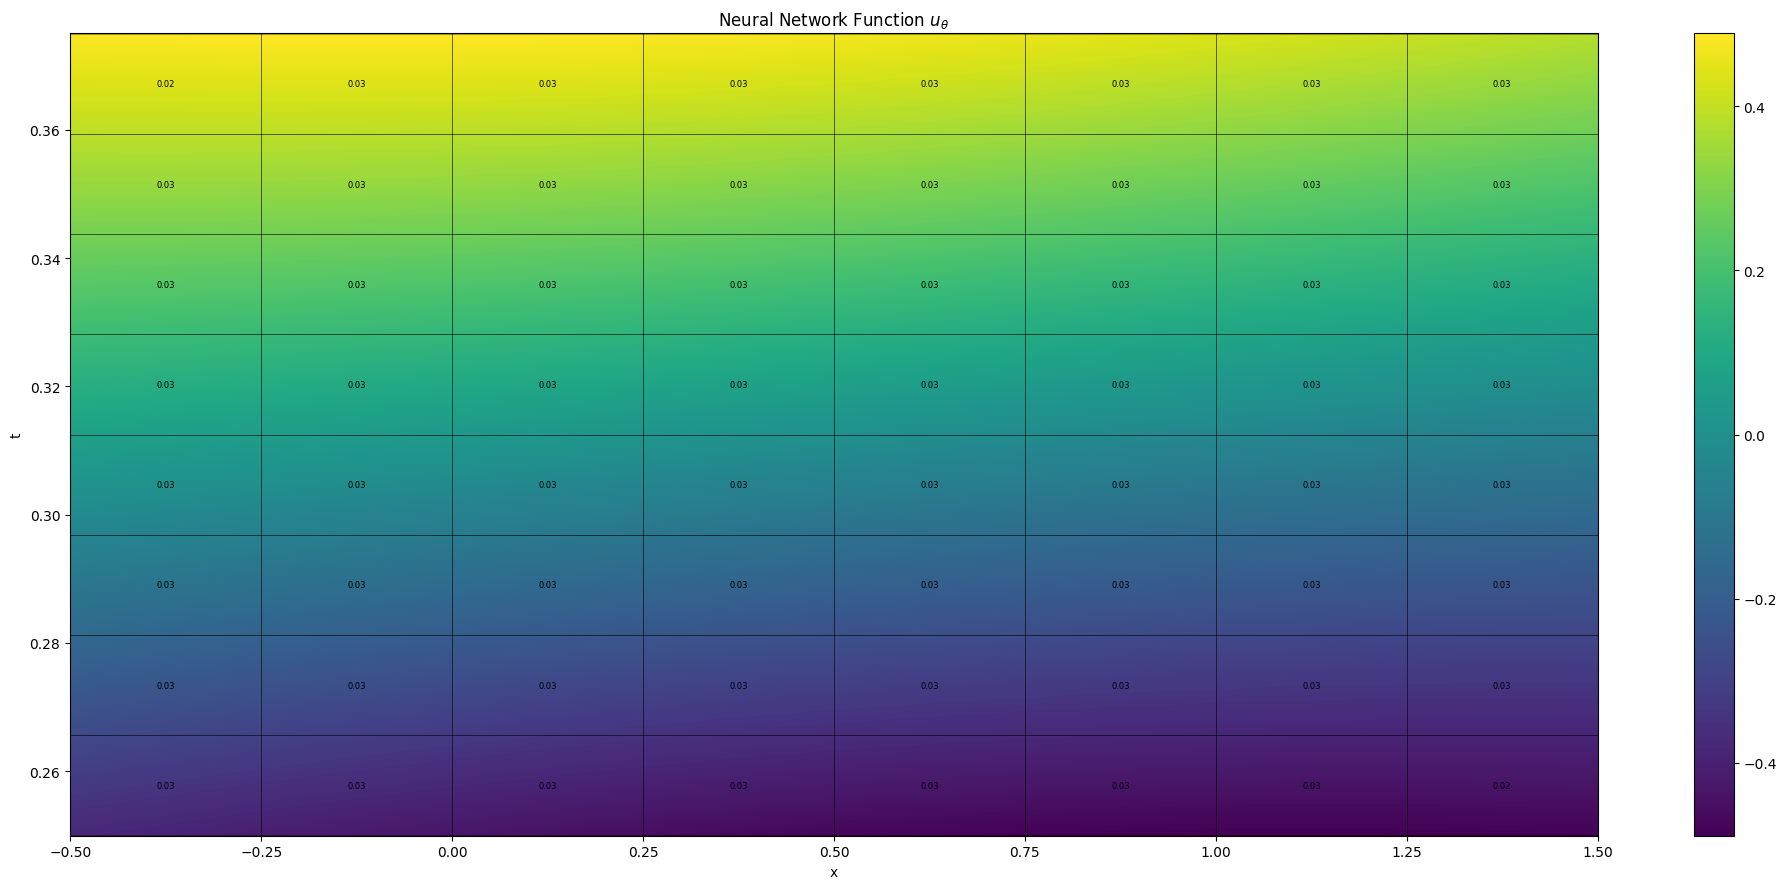

Grade 0, Iter 100, loss_eqn: 0.642621, loss_eqn_from_kh: 0.642621, loss_l1: 0.642621, loss_ibc: 1.156240
Grade 0, Iter 200, loss_eqn: 0.998787, loss_eqn_from_kh: 0.998787, loss_l1: 0.998787, loss_ibc: 0.918559
Grade 0, Iter 300, loss_eqn: 0.740360, loss_eqn_from_kh: 0.740360, loss_l1: 0.740360, loss_ibc: 0.278160
Grade 0, Iter 400, loss_eqn: 0.640778, loss_eqn_from_kh: 0.640778, loss_l1: 0.640778, loss_ibc: 0.099840
Grade 0, Iter 500, loss_eqn: 0.546618, loss_eqn_from_kh: 0.546618, loss_l1: 0.546618, loss_ibc: 0.058266
Grade 0, Iter 600, loss_eqn: 0.517361, loss_eqn_from_kh: 0.517361, loss_l1: 0.517361, loss_ibc: 0.043732
Grade 0, Iter 700, loss_eqn: 0.446667, loss_eqn_from_kh: 0.446667, loss_l1: 0.446667, loss_ibc: 0.039981
Grade 0, Iter 800, loss_eqn: 0.383406, loss_eqn_from_kh: 0.383406, loss_l1: 0.383406, loss_ibc: 0.024931
Grade 0, Iter 900, loss_eqn: 0.467261, loss_eqn_from_kh: 0.467261, loss_l1: 0.468507, loss_ibc: 0.013290
Grade 0, Iter 1000, lambda_ic: 9.604883, lambda_bc: 11.

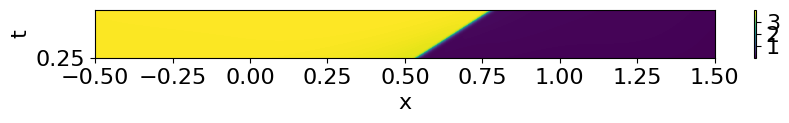

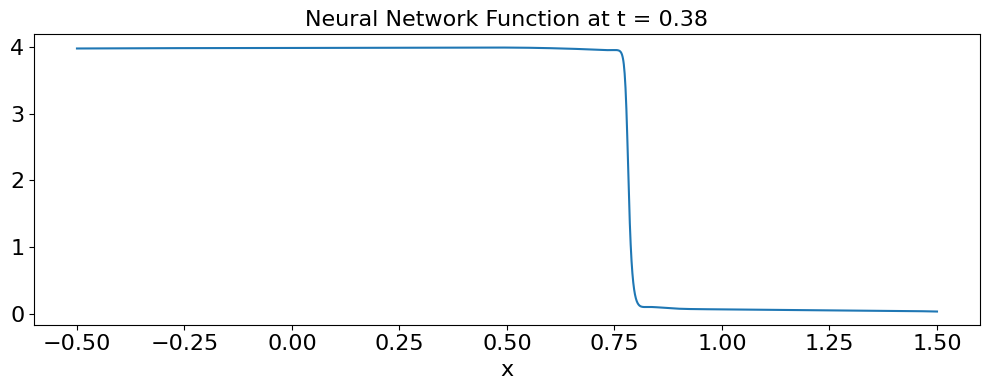

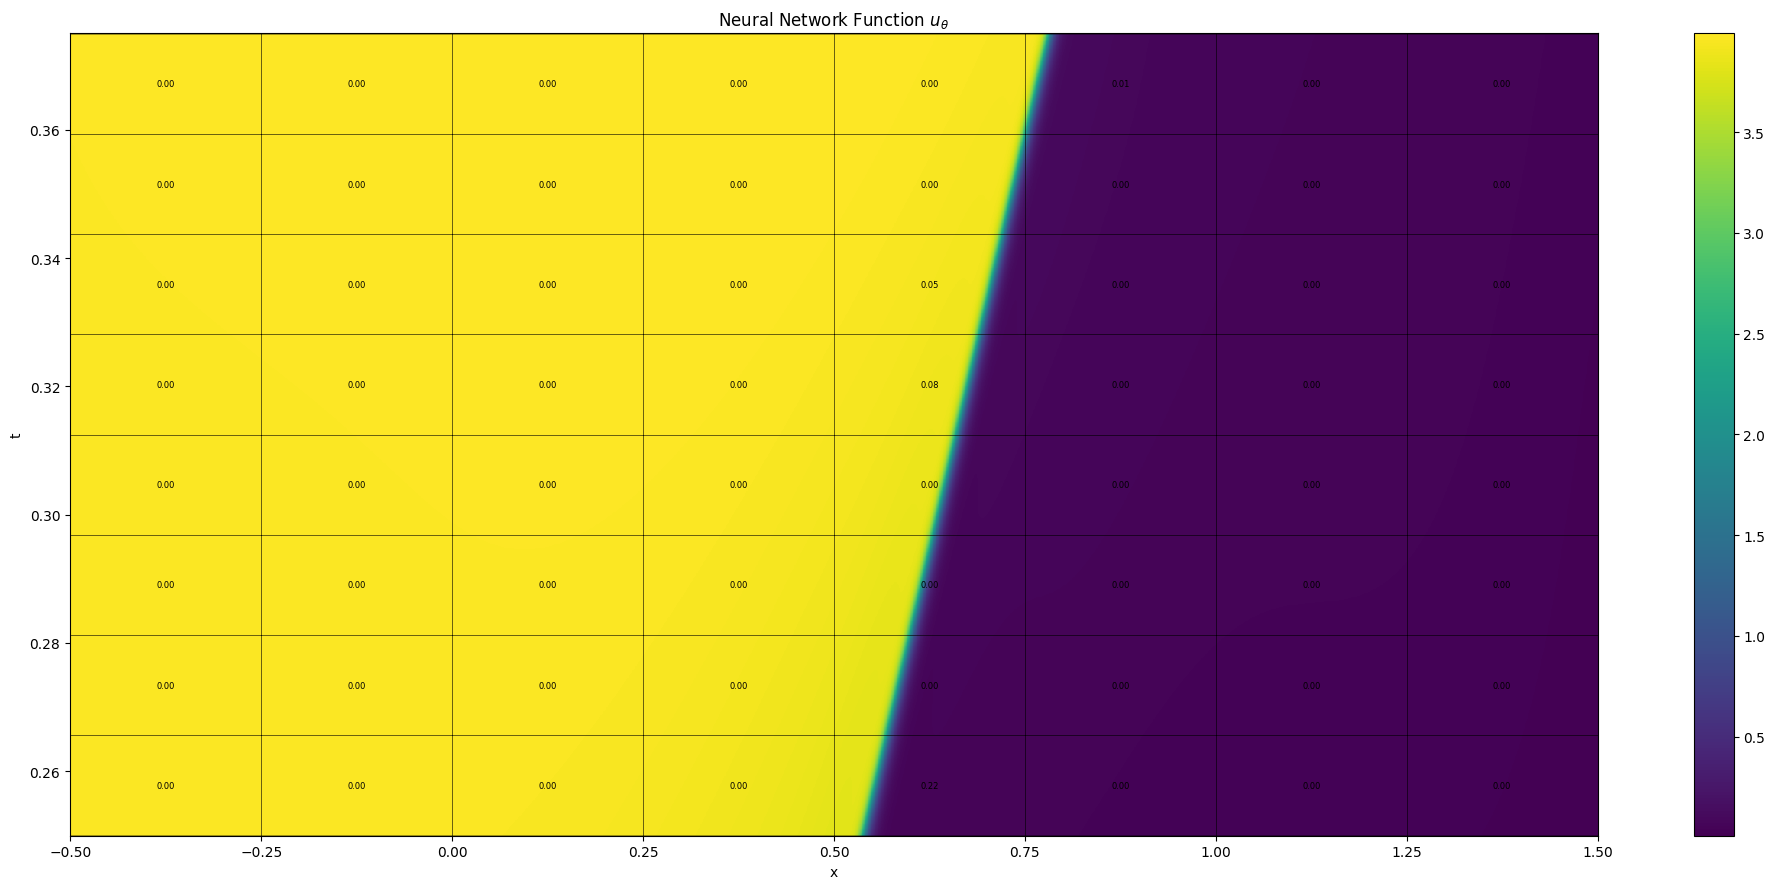

Grade 0, Iter 1100, loss_eqn: 0.374153, loss_eqn_from_kh: 0.374153, loss_l1: 0.374566, loss_ibc: 0.009701
Grade 0, Iter 1200, loss_eqn: 0.181496, loss_eqn_from_kh: 0.181496, loss_l1: 0.181497, loss_ibc: 0.014404
Grade 0, Iter 1300, loss_eqn: 0.370888, loss_eqn_from_kh: 0.370888, loss_l1: 0.370888, loss_ibc: 0.018179
Grade 0, Iter 1400, loss_eqn: 0.150271, loss_eqn_from_kh: 0.150271, loss_l1: 0.150271, loss_ibc: 0.011943
Grade 0, Iter 1500, loss_eqn: 0.190531, loss_eqn_from_kh: 0.190531, loss_l1: 0.190531, loss_ibc: 0.009627
Grade 0, Iter 1600, loss_eqn: 0.142263, loss_eqn_from_kh: 0.142263, loss_l1: 0.142263, loss_ibc: 0.015322
Grade 0, Iter 1700, loss_eqn: 0.166147, loss_eqn_from_kh: 0.166146, loss_l1: 0.166146, loss_ibc: 0.009265
Grade 0, Iter 1800, loss_eqn: 0.179906, loss_eqn_from_kh: 0.179906, loss_l1: 0.179906, loss_ibc: 0.009350
Grade 0, Iter 1900, loss_eqn: 0.130849, loss_eqn_from_kh: 0.130849, loss_l1: 0.130849, loss_ibc: 0.012628
Grade 0, Iter 2000, lambda_ic: 11.759670, lamb

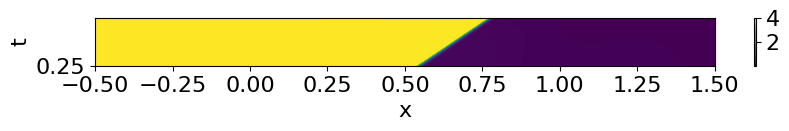

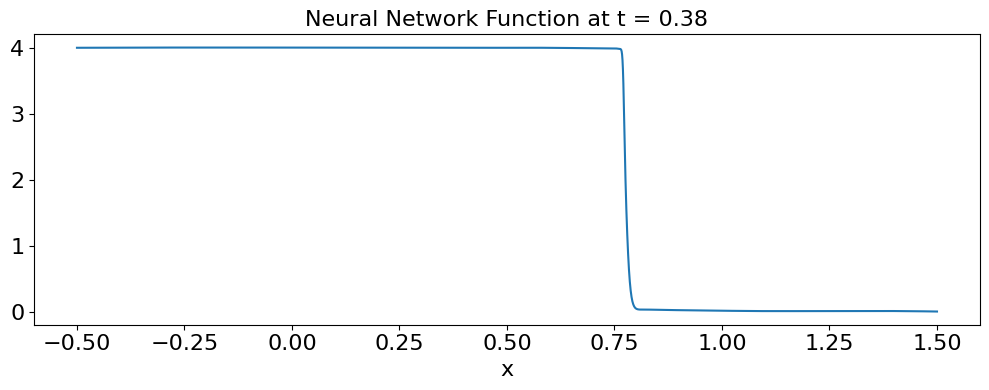

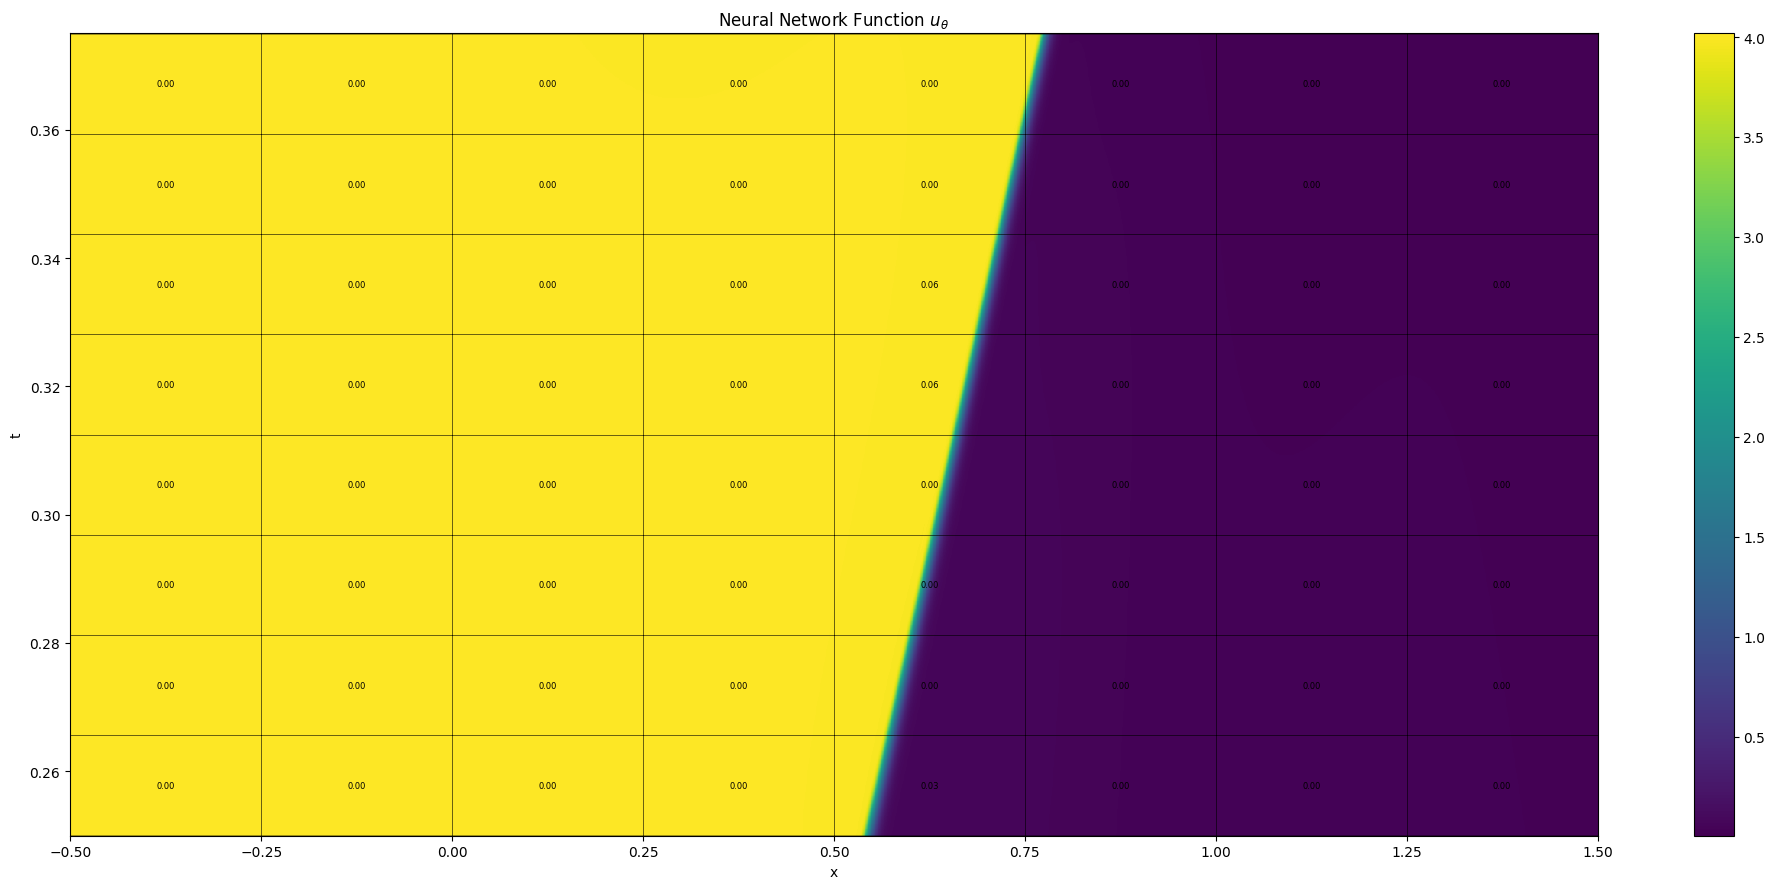

Grade 0, Iter 2100, loss_eqn: 0.163090, loss_eqn_from_kh: 0.163090, loss_l1: 0.163090, loss_ibc: 0.013055
Grade 0, Iter 2200, loss_eqn: 0.118661, loss_eqn_from_kh: 0.118661, loss_l1: 0.118661, loss_ibc: 0.007078
Grade 0, Iter 2300, loss_eqn: 0.128480, loss_eqn_from_kh: 0.128480, loss_l1: 0.128480, loss_ibc: 0.010275
Grade 0, Iter 2400, loss_eqn: 0.111743, loss_eqn_from_kh: 0.111743, loss_l1: 0.111743, loss_ibc: 0.006501
Grade 0, Iter 2500, loss_eqn: 0.077709, loss_eqn_from_kh: 0.077709, loss_l1: 0.077709, loss_ibc: 0.008369
Grade 0, Iter 2600, loss_eqn: 0.082558, loss_eqn_from_kh: 0.082558, loss_l1: 0.082558, loss_ibc: 0.006023
Grade 0, Iter 2700, loss_eqn: 0.093660, loss_eqn_from_kh: 0.093660, loss_l1: 0.093660, loss_ibc: 0.008667
Grade 0, Iter 2800, loss_eqn: 0.045683, loss_eqn_from_kh: 0.045683, loss_l1: 0.045683, loss_ibc: 0.008300
Grade 0, Iter 2900, loss_eqn: 0.017747, loss_eqn_from_kh: 0.017747, loss_l1: 0.017747, loss_ibc: 0.006021
Grade 0, Iter 3000, lambda_ic: 13.052931, lamb

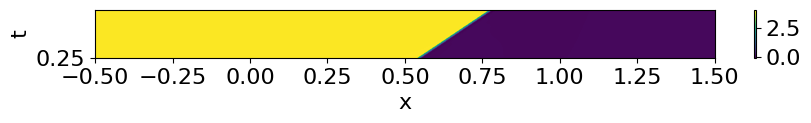

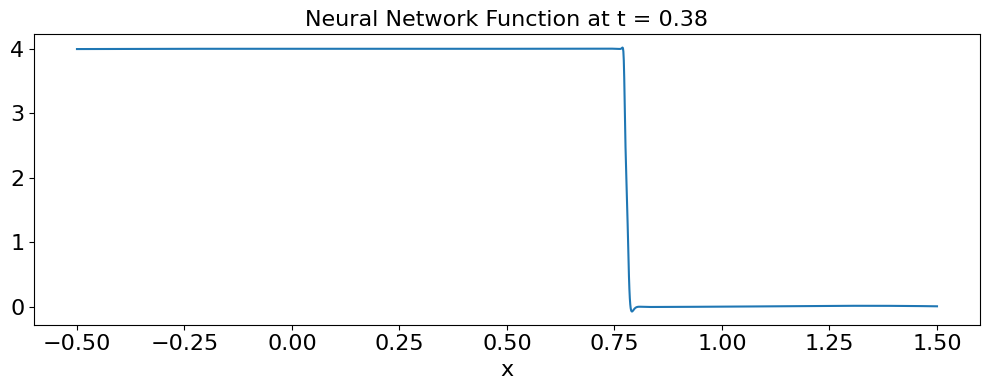

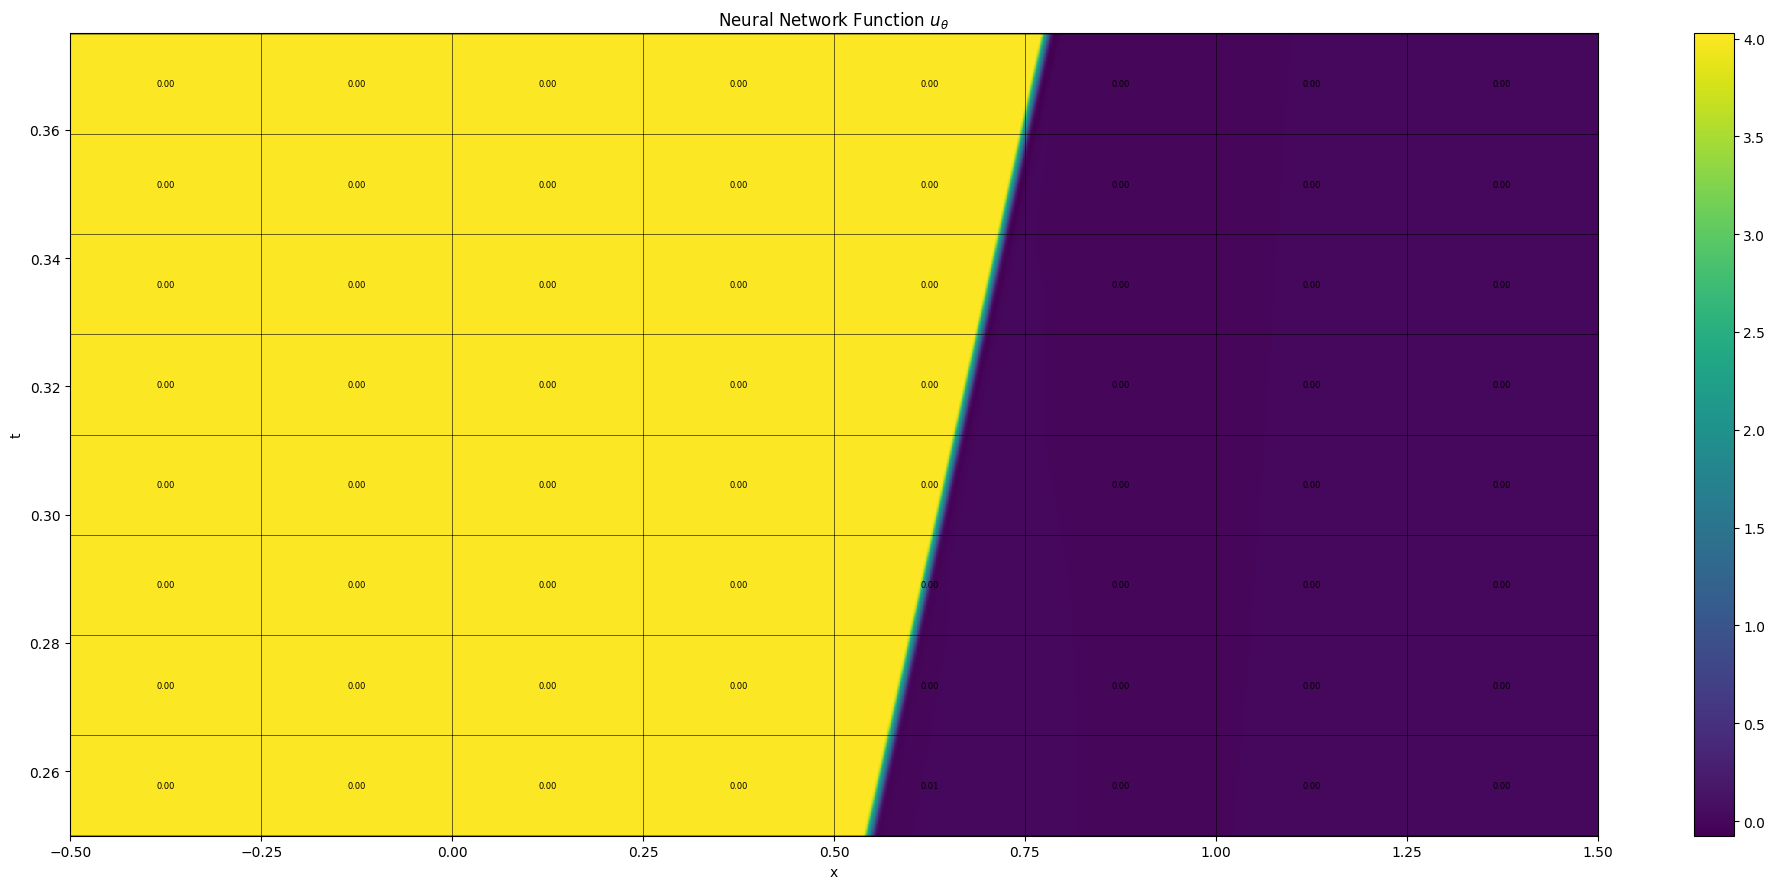

Grade 0, Iter 3100, loss_eqn: 0.044835, loss_eqn_from_kh: 0.044835, loss_l1: 0.044835, loss_ibc: 0.009184
Grade 0, Iter 3200, loss_eqn: 0.023415, loss_eqn_from_kh: 0.023415, loss_l1: 0.023415, loss_ibc: 0.006164
Grade 0, Iter 3300, loss_eqn: 0.039578, loss_eqn_from_kh: 0.039578, loss_l1: 0.039578, loss_ibc: 0.005872
Grade 0, Iter 3400, loss_eqn: 0.040277, loss_eqn_from_kh: 0.040277, loss_l1: 0.040277, loss_ibc: 0.006078
Grade 0, Iter 3500, loss_eqn: 0.061926, loss_eqn_from_kh: 0.061926, loss_l1: 0.061926, loss_ibc: 0.004975
Grade 0, Iter 3600, loss_eqn: 0.013410, loss_eqn_from_kh: 0.013410, loss_l1: 0.013410, loss_ibc: 0.006363
Grade 0, Iter 3700, loss_eqn: 0.028494, loss_eqn_from_kh: 0.028494, loss_l1: 0.028494, loss_ibc: 0.005330
Grade 0, Iter 3800, loss_eqn: 0.011794, loss_eqn_from_kh: 0.011794, loss_l1: 0.011794, loss_ibc: 0.007662
Grade 0, Iter 3900, loss_eqn: 0.009979, loss_eqn_from_kh: 0.009979, loss_l1: 0.009979, loss_ibc: 0.006791
Grade 0, Iter 4000, lambda_ic: 13.447645, lamb

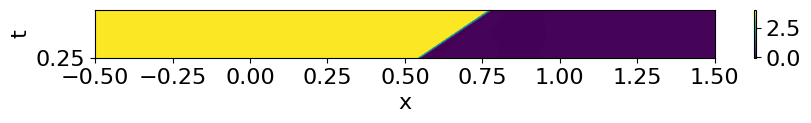

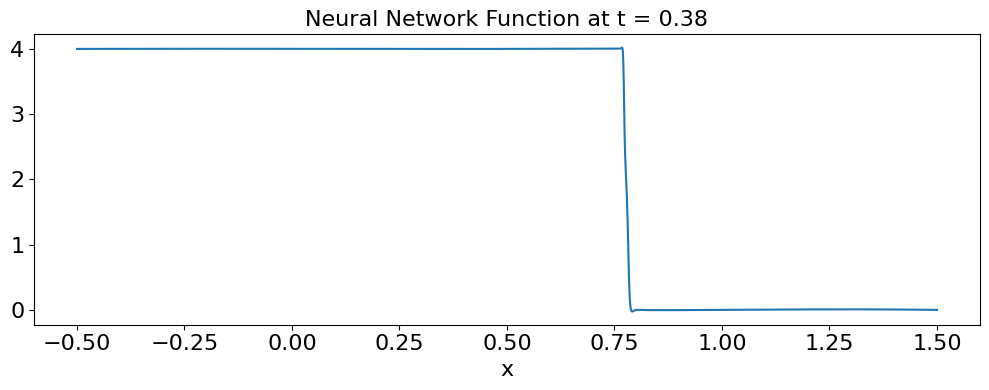

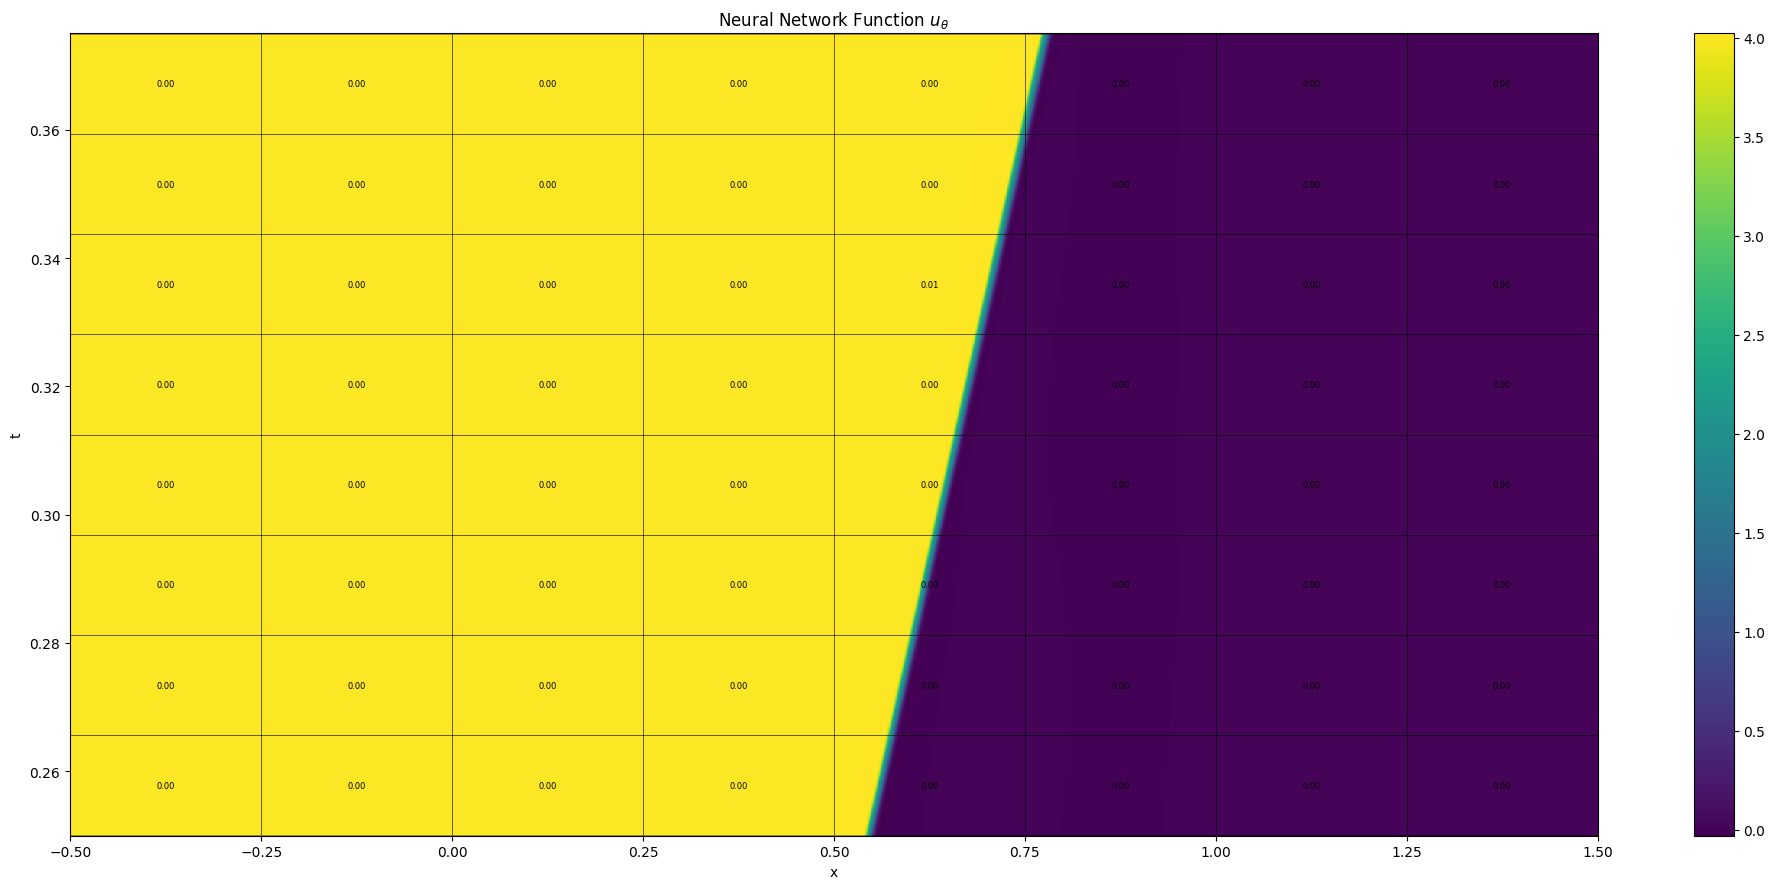

Grade 0, Iter 4100, loss_eqn: 0.012092, loss_eqn_from_kh: 0.012092, loss_l1: 0.012092, loss_ibc: 0.005760
Grade 0, Iter 4200, loss_eqn: 0.007160, loss_eqn_from_kh: 0.007160, loss_l1: 0.007160, loss_ibc: 0.006161
Grade 0, Iter 4300, loss_eqn: 0.009206, loss_eqn_from_kh: 0.009206, loss_l1: 0.009228, loss_ibc: 0.006468
Grade 0, Iter 4400, loss_eqn: 0.003893, loss_eqn_from_kh: 0.003893, loss_l1: 0.003896, loss_ibc: 0.006185
Grade 0, Iter 4500, loss_eqn: 0.011675, loss_eqn_from_kh: 0.011675, loss_l1: 0.011683, loss_ibc: 0.006114
Grade 0, Iter 4600, loss_eqn: 0.007722, loss_eqn_from_kh: 0.007722, loss_l1: 0.007724, loss_ibc: 0.006030
Grade 0, Iter 4700, loss_eqn: 0.009110, loss_eqn_from_kh: 0.009110, loss_l1: 0.009110, loss_ibc: 0.005932


In [ ]:
seq_trainer.train_seq()

Adding grade 1 with hidden dims [64, 64, 64, 64, 64]

Training segment [0.0000, 0.1667]
Skipping pre-training as pre_epochs is set to 0.

Starting Train Stage with MGDL

Stage 1: Sequential Grade Training

Training Grade 0
The largest W^{1,inf} norm of k_h coeffs is 3.176214
Grade 0, Iter 0, lambda_ic: 9.299298, lambda_bc: 9.558501, lambda_eqn: 1.105409
Grade 0, Iter 0, loss_eqn: 1.832305, loss_eqn_from_kh: 1.832308, loss_l1: 1.832308, loss_ibc: 20.663330


C:\Users\hao6li\Projects\NN-HCL\Code\my_helpers.py:156: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


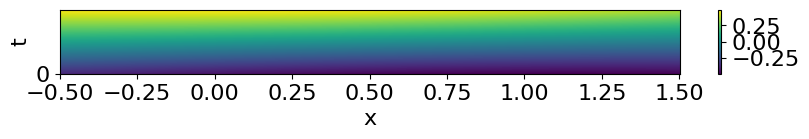

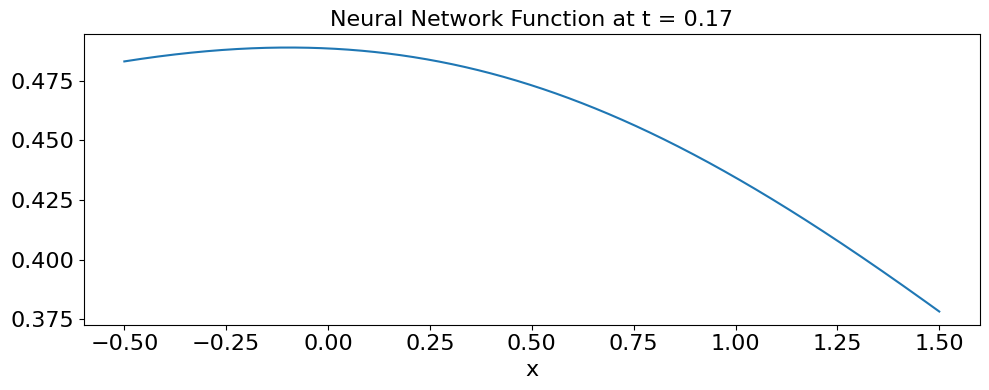

Grade 0, Iter 100, loss_eqn: 1.446011, loss_eqn_from_kh: 1.446013, loss_l1: 1.447376, loss_ibc: 1.598279
Grade 0, Iter 200, loss_eqn: 1.530053, loss_eqn_from_kh: 1.530046, loss_l1: 1.548249, loss_ibc: 0.306427
Grade 0, Iter 300, loss_eqn: 0.561842, loss_eqn_from_kh: 0.561840, loss_l1: 0.868931, loss_ibc: 0.096510
Grade 0, Iter 400, loss_eqn: 0.359147, loss_eqn_from_kh: 0.359144, loss_l1: 0.785175, loss_ibc: 0.048449
Grade 0, Iter 500, loss_eqn: 0.319680, loss_eqn_from_kh: 0.319679, loss_l1: 0.731898, loss_ibc: 0.037682
Grade 0, Iter 600, loss_eqn: 0.339266, loss_eqn_from_kh: 0.339267, loss_l1: 0.734215, loss_ibc: 0.032974
Grade 0, Iter 700, loss_eqn: 0.323791, loss_eqn_from_kh: 0.323790, loss_l1: 0.731599, loss_ibc: 0.028944
Grade 0, Iter 800, loss_eqn: 0.324738, loss_eqn_from_kh: 0.324738, loss_l1: 0.737742, loss_ibc: 0.027891
Grade 0, Iter 900, loss_eqn: 0.331998, loss_eqn_from_kh: 0.331999, loss_l1: 0.731666, loss_ibc: 0.021934
Grade 0, Iter 1000, lambda_ic: 9.057318, lambda_bc: 9.6

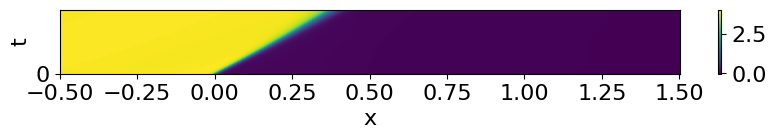

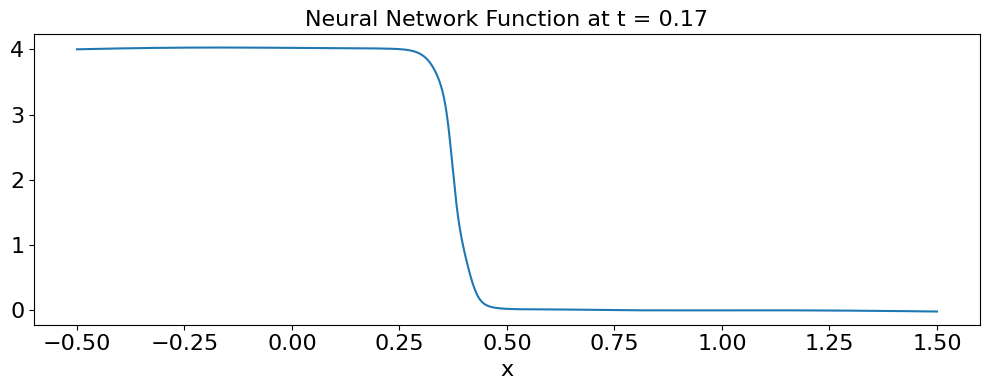

Grade 0, Iter 1100, loss_eqn: 0.317550, loss_eqn_from_kh: 0.317550, loss_l1: 0.719934, loss_ibc: 0.017744
Grade 0, Iter 1200, loss_eqn: 0.279513, loss_eqn_from_kh: 0.279513, loss_l1: 0.704325, loss_ibc: 0.014783
Grade 0, Iter 1300, loss_eqn: 0.283490, loss_eqn_from_kh: 0.283492, loss_l1: 0.749439, loss_ibc: 0.014267
Grade 0, Iter 1400, loss_eqn: 0.199132, loss_eqn_from_kh: 0.199133, loss_l1: 0.655114, loss_ibc: 0.013069
Grade 0, Iter 1500, loss_eqn: 0.264894, loss_eqn_from_kh: 0.264894, loss_l1: 0.669010, loss_ibc: 0.012899
Grade 0, Iter 1600, loss_eqn: 0.214108, loss_eqn_from_kh: 0.214108, loss_l1: 0.663529, loss_ibc: 0.020711
Grade 0, Iter 1700, loss_eqn: 0.156164, loss_eqn_from_kh: 0.156164, loss_l1: 0.633028, loss_ibc: 0.010868
Grade 0, Iter 1800, loss_eqn: 0.199104, loss_eqn_from_kh: 0.199103, loss_l1: 0.670855, loss_ibc: 0.011248
Grade 0, Iter 1900, loss_eqn: 0.141005, loss_eqn_from_kh: 0.141005, loss_l1: 0.599069, loss_ibc: 0.010820
Grade 0, Iter 2000, lambda_ic: 11.246575, lamb

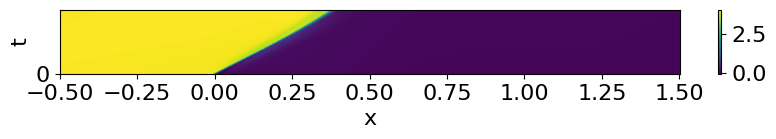

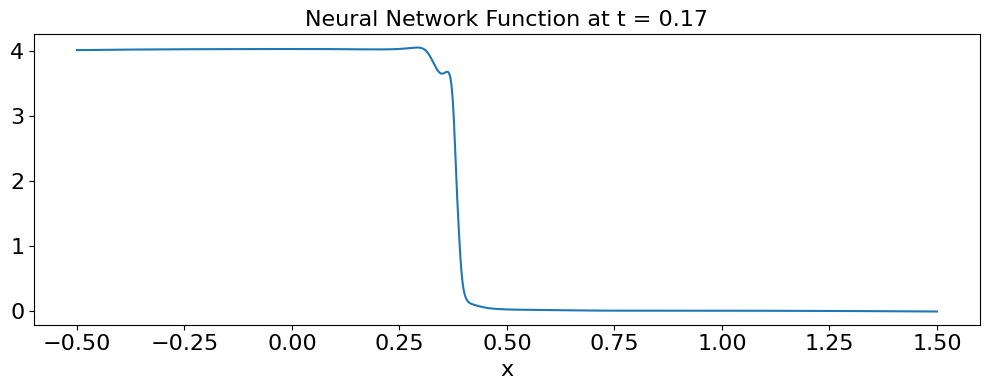

Grade 0, Iter 2100, loss_eqn: 0.184290, loss_eqn_from_kh: 0.184291, loss_l1: 0.637391, loss_ibc: 0.009675
Grade 0, Iter 2200, loss_eqn: 0.145785, loss_eqn_from_kh: 0.145785, loss_l1: 0.595821, loss_ibc: 0.008613
Grade 0, Iter 2300, loss_eqn: 0.105888, loss_eqn_from_kh: 0.105888, loss_l1: 0.533408, loss_ibc: 0.009730
Grade 0, Iter 2400, loss_eqn: 0.088013, loss_eqn_from_kh: 0.088013, loss_l1: 0.515718, loss_ibc: 0.008534
Grade 0, Iter 2500, loss_eqn: 0.114658, loss_eqn_from_kh: 0.114658, loss_l1: 0.563516, loss_ibc: 0.008899
Grade 0, Iter 2600, loss_eqn: 0.103203, loss_eqn_from_kh: 0.103203, loss_l1: 0.533008, loss_ibc: 0.008557
Grade 0, Iter 2700, loss_eqn: 0.067932, loss_eqn_from_kh: 0.067932, loss_l1: 0.487922, loss_ibc: 0.008348
Grade 0, Iter 2800, loss_eqn: 0.083261, loss_eqn_from_kh: 0.083261, loss_l1: 0.498738, loss_ibc: 0.009055
Grade 0, Iter 2900, loss_eqn: 0.055751, loss_eqn_from_kh: 0.055751, loss_l1: 0.464598, loss_ibc: 0.008275
Grade 0, Iter 3000, lambda_ic: 11.836327, lamb

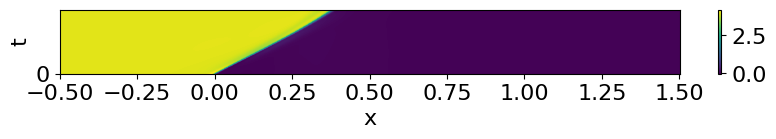

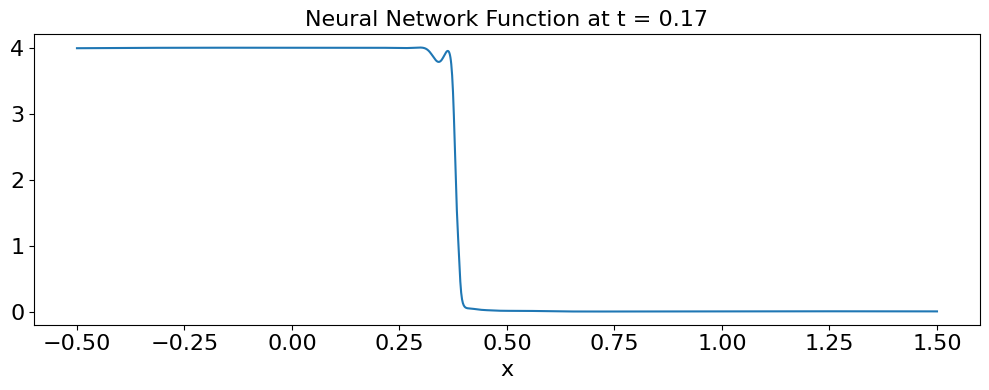

Grade 0, Iter 3100, loss_eqn: 0.059364, loss_eqn_from_kh: 0.059364, loss_l1: 0.460744, loss_ibc: 0.007760
Grade 0, Iter 3200, loss_eqn: 0.049535, loss_eqn_from_kh: 0.049535, loss_l1: 0.422636, loss_ibc: 0.008107
Grade 0, Iter 3300, loss_eqn: 0.065141, loss_eqn_from_kh: 0.065141, loss_l1: 0.416463, loss_ibc: 0.008726
Grade 0, Iter 3400, loss_eqn: 0.036100, loss_eqn_from_kh: 0.036099, loss_l1: 0.398181, loss_ibc: 0.008235
Grade 0, Iter 3500, loss_eqn: 0.045722, loss_eqn_from_kh: 0.045722, loss_l1: 0.383018, loss_ibc: 0.007122
Grade 0, Iter 3600, loss_eqn: 0.032716, loss_eqn_from_kh: 0.032716, loss_l1: 0.385865, loss_ibc: 0.007691
Grade 0, Iter 3700, loss_eqn: 0.029841, loss_eqn_from_kh: 0.029841, loss_l1: 0.373880, loss_ibc: 0.007173
Grade 0, Iter 3800, loss_eqn: 0.027915, loss_eqn_from_kh: 0.027915, loss_l1: 0.378844, loss_ibc: 0.006945
Grade 0, Iter 3900, loss_eqn: 0.035524, loss_eqn_from_kh: 0.035524, loss_l1: 0.364240, loss_ibc: 0.007569
Grade 0, Iter 4000, lambda_ic: 13.560509, lamb

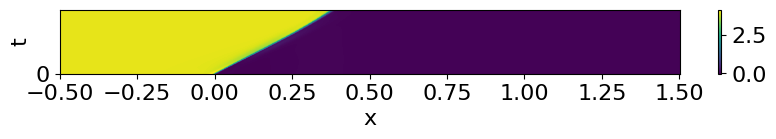

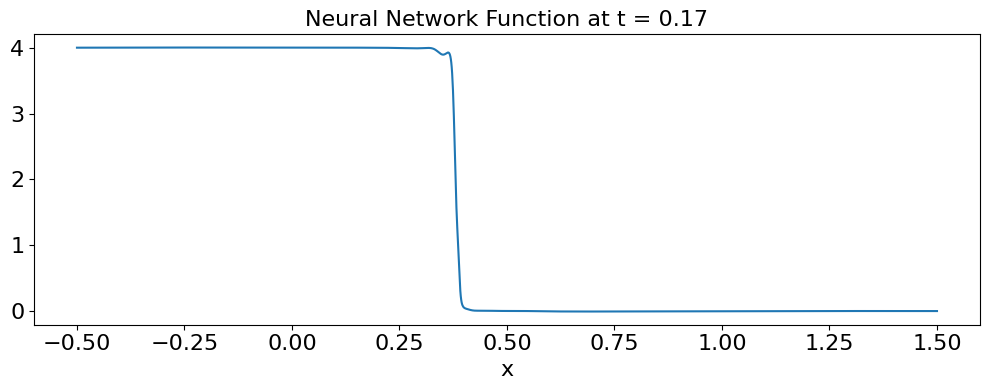

Grade 0, Iter 4100, loss_eqn: 0.024979, loss_eqn_from_kh: 0.024979, loss_l1: 0.369668, loss_ibc: 0.006748
Grade 0, Iter 4200, loss_eqn: 0.027977, loss_eqn_from_kh: 0.027977, loss_l1: 0.366474, loss_ibc: 0.006423
Grade 0, Iter 4300, loss_eqn: 0.023244, loss_eqn_from_kh: 0.023244, loss_l1: 0.374058, loss_ibc: 0.006294
Grade 0, Iter 4400, loss_eqn: 0.028824, loss_eqn_from_kh: 0.028824, loss_l1: 0.362908, loss_ibc: 0.006601
Grade 0, Iter 4500, loss_eqn: 0.026558, loss_eqn_from_kh: 0.026558, loss_l1: 0.376805, loss_ibc: 0.006292
Grade 0, Iter 4600, loss_eqn: 0.022377, loss_eqn_from_kh: 0.022377, loss_l1: 0.371677, loss_ibc: 0.006166
Grade 0, Iter 4700, loss_eqn: 0.023087, loss_eqn_from_kh: 0.023087, loss_l1: 0.375122, loss_ibc: 0.006107
Grade 0, Iter 4800, loss_eqn: 0.022475, loss_eqn_from_kh: 0.022475, loss_l1: 0.373614, loss_ibc: 0.006071
Grade 0, Iter 4900, loss_eqn: 0.022901, loss_eqn_from_kh: 0.022901, loss_l1: 0.374970, loss_ibc: 0.006048
Train time for stage1: 749.813552 seconds

Plo

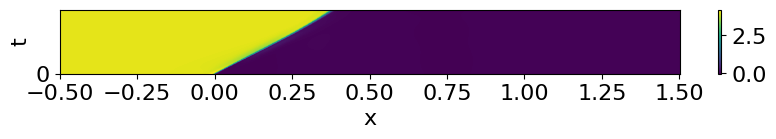

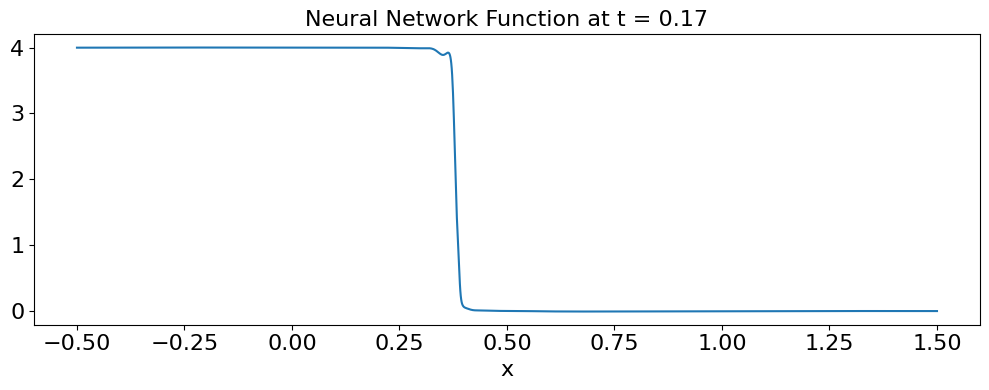

Adding grade 1 with hidden dims [64, 64, 64, 64, 64]

Training segment [0.1667, 0.3333]
Skipping pre-training as pre_epochs is set to 0.

Starting Train Stage with MGDL

Stage 1: Sequential Grade Training

Training Grade 0
The largest W^{1,inf} norm of k_h coeffs is 3.176214
Grade 0, Iter 0, lambda_ic: 9.227148, lambda_bc: 9.664390, lambda_eqn: 1.144353
Grade 0, Iter 0, loss_eqn: 1.832168, loss_eqn_from_kh: 1.832174, loss_l1: 1.832174, loss_ibc: 24.350294


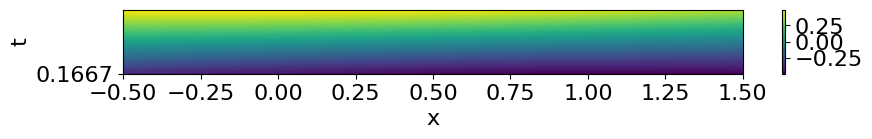

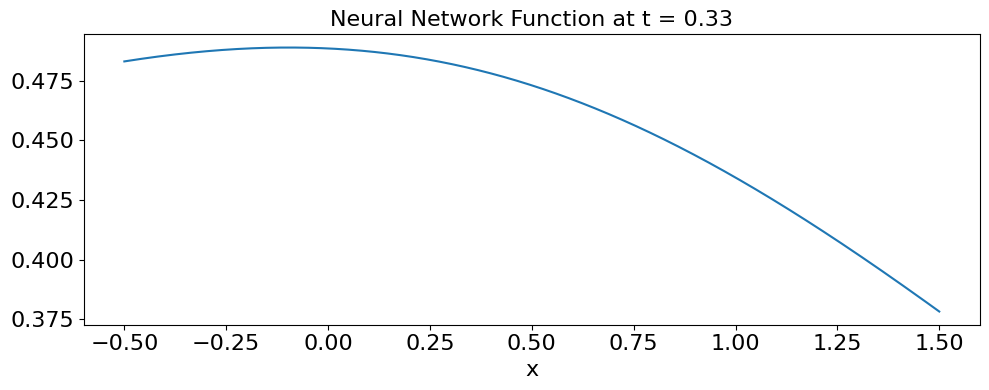

Grade 0, Iter 100, loss_eqn: 0.816122, loss_eqn_from_kh: 0.816123, loss_l1: 0.816440, loss_ibc: 1.222794
Grade 0, Iter 200, loss_eqn: 1.311412, loss_eqn_from_kh: 1.311409, loss_l1: 1.312808, loss_ibc: 0.887153
Grade 0, Iter 300, loss_eqn: 0.685834, loss_eqn_from_kh: 0.685834, loss_l1: 0.854622, loss_ibc: 0.153349
Grade 0, Iter 400, loss_eqn: 0.379305, loss_eqn_from_kh: 0.379305, loss_l1: 0.763530, loss_ibc: 0.041814
Grade 0, Iter 500, loss_eqn: 0.306531, loss_eqn_from_kh: 0.306531, loss_l1: 0.753664, loss_ibc: 0.021309
Grade 0, Iter 600, loss_eqn: 0.295386, loss_eqn_from_kh: 0.295387, loss_l1: 0.722966, loss_ibc: 0.020709
Grade 0, Iter 700, loss_eqn: 0.281249, loss_eqn_from_kh: 0.281250, loss_l1: 0.705685, loss_ibc: 0.017480
Grade 0, Iter 800, loss_eqn: 0.279714, loss_eqn_from_kh: 0.279713, loss_l1: 0.701165, loss_ibc: 0.016929
Grade 0, Iter 900, loss_eqn: 0.279453, loss_eqn_from_kh: 0.279454, loss_l1: 0.695318, loss_ibc: 0.016100
Grade 0, Iter 1000, lambda_ic: 10.481515, lambda_bc: 11

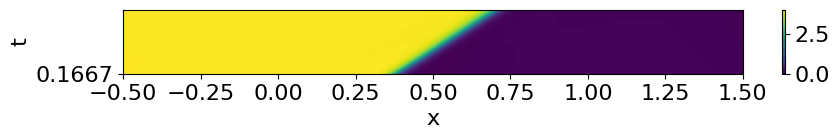

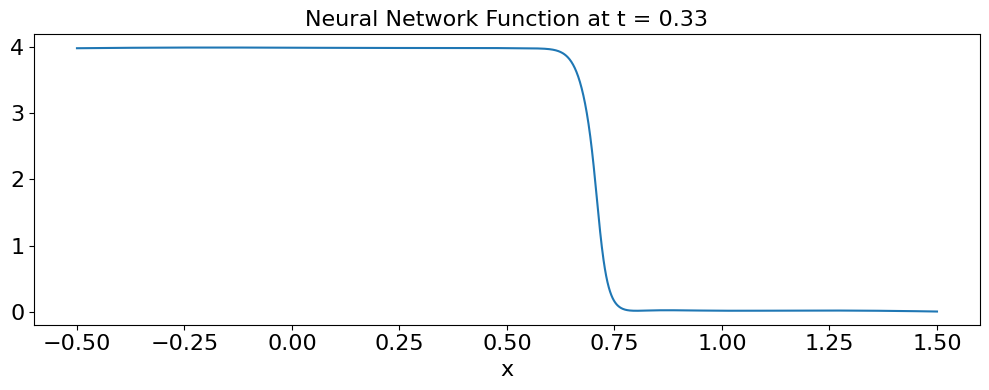

Grade 0, Iter 1100, loss_eqn: 0.278105, loss_eqn_from_kh: 0.278105, loss_l1: 0.706019, loss_ibc: 0.013334
Grade 0, Iter 1200, loss_eqn: 0.287742, loss_eqn_from_kh: 0.287742, loss_l1: 0.713328, loss_ibc: 0.011523
Grade 0, Iter 1300, loss_eqn: 0.284359, loss_eqn_from_kh: 0.284358, loss_l1: 0.708819, loss_ibc: 0.010366
Grade 0, Iter 1400, loss_eqn: 0.311212, loss_eqn_from_kh: 0.311212, loss_l1: 0.730459, loss_ibc: 0.009374
Grade 0, Iter 1500, loss_eqn: 0.301283, loss_eqn_from_kh: 0.301281, loss_l1: 0.724948, loss_ibc: 0.008535
Grade 0, Iter 1600, loss_eqn: 0.269327, loss_eqn_from_kh: 0.269328, loss_l1: 0.691818, loss_ibc: 0.007694
Grade 0, Iter 1700, loss_eqn: 0.263614, loss_eqn_from_kh: 0.263615, loss_l1: 0.676875, loss_ibc: 0.007055
Grade 0, Iter 1800, loss_eqn: 0.239273, loss_eqn_from_kh: 0.239274, loss_l1: 0.648832, loss_ibc: 0.006093
Grade 0, Iter 1900, loss_eqn: 0.229223, loss_eqn_from_kh: 0.229224, loss_l1: 0.614335, loss_ibc: 0.004857
Grade 0, Iter 2000, lambda_ic: 12.663878, lamb

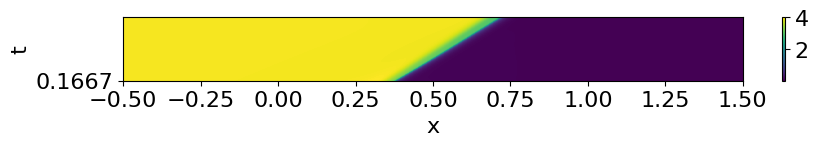

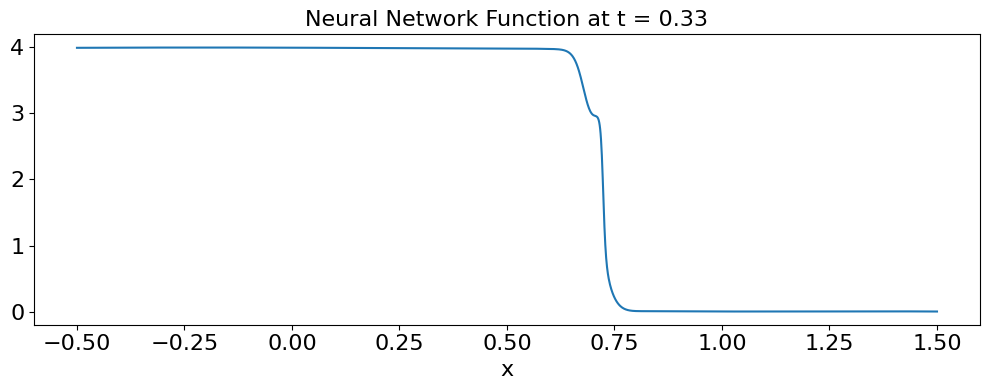

Grade 0, Iter 2100, loss_eqn: 0.208157, loss_eqn_from_kh: 0.208157, loss_l1: 0.592469, loss_ibc: 0.002591
Grade 0, Iter 2200, loss_eqn: 0.191034, loss_eqn_from_kh: 0.191034, loss_l1: 0.665402, loss_ibc: 0.003637
Grade 0, Iter 2300, loss_eqn: 0.222180, loss_eqn_from_kh: 0.222180, loss_l1: 0.729513, loss_ibc: 0.002319
Grade 0, Iter 2400, loss_eqn: 0.173215, loss_eqn_from_kh: 0.173213, loss_l1: 0.623520, loss_ibc: 0.002857
Grade 0, Iter 2500, loss_eqn: 0.174129, loss_eqn_from_kh: 0.174130, loss_l1: 0.649622, loss_ibc: 0.003212
Grade 0, Iter 2600, loss_eqn: 0.168951, loss_eqn_from_kh: 0.168952, loss_l1: 0.616368, loss_ibc: 0.001343
Grade 0, Iter 2700, loss_eqn: 0.161607, loss_eqn_from_kh: 0.161606, loss_l1: 0.635555, loss_ibc: 0.001421
Grade 0, Iter 2800, loss_eqn: 0.155069, loss_eqn_from_kh: 0.155068, loss_l1: 0.603604, loss_ibc: 0.001484
Grade 0, Iter 2900, loss_eqn: 0.152380, loss_eqn_from_kh: 0.152379, loss_l1: 0.605397, loss_ibc: 0.001362
Grade 0, Iter 3000, lambda_ic: 13.257275, lamb

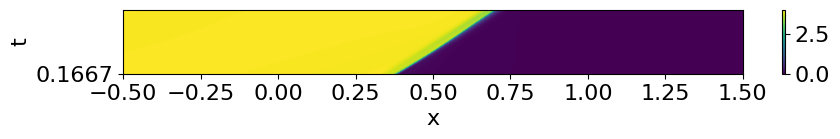

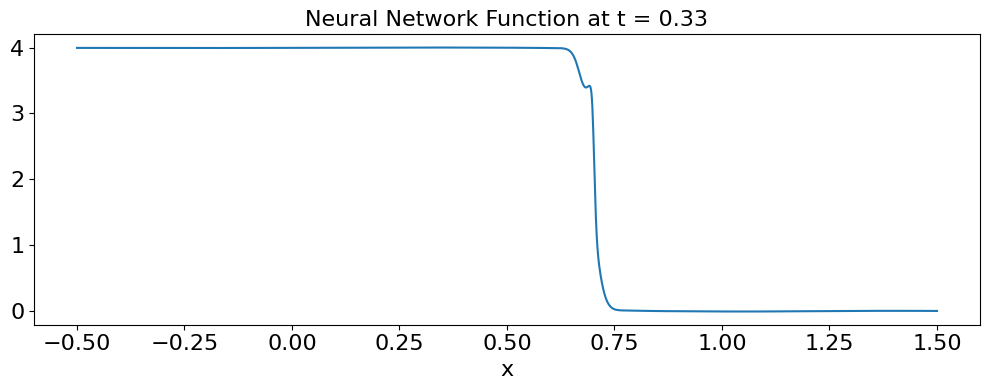

Grade 0, Iter 3100, loss_eqn: 0.140576, loss_eqn_from_kh: 0.140576, loss_l1: 0.586707, loss_ibc: 0.001368
Grade 0, Iter 3200, loss_eqn: 0.141839, loss_eqn_from_kh: 0.141838, loss_l1: 0.582497, loss_ibc: 0.001128
Grade 0, Iter 3300, loss_eqn: 0.145711, loss_eqn_from_kh: 0.145711, loss_l1: 0.569531, loss_ibc: 0.001138
Grade 0, Iter 3400, loss_eqn: 0.130276, loss_eqn_from_kh: 0.130275, loss_l1: 0.570500, loss_ibc: 0.001403
Grade 0, Iter 3500, loss_eqn: 0.133826, loss_eqn_from_kh: 0.133826, loss_l1: 0.569761, loss_ibc: 0.001200
Grade 0, Iter 3600, loss_eqn: 0.121194, loss_eqn_from_kh: 0.121193, loss_l1: 0.566274, loss_ibc: 0.001290
Grade 0, Iter 3700, loss_eqn: 0.120318, loss_eqn_from_kh: 0.120318, loss_l1: 0.565958, loss_ibc: 0.001445
Grade 0, Iter 3800, loss_eqn: 0.118479, loss_eqn_from_kh: 0.118479, loss_l1: 0.558744, loss_ibc: 0.001772
Grade 0, Iter 3900, loss_eqn: 0.115544, loss_eqn_from_kh: 0.115544, loss_l1: 0.558856, loss_ibc: 0.001304
Grade 0, Iter 4000, lambda_ic: 14.390984, lamb

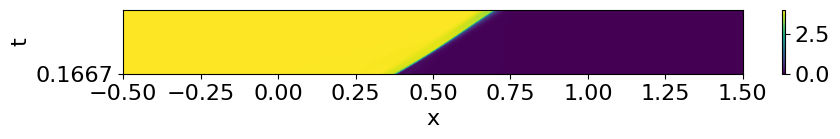

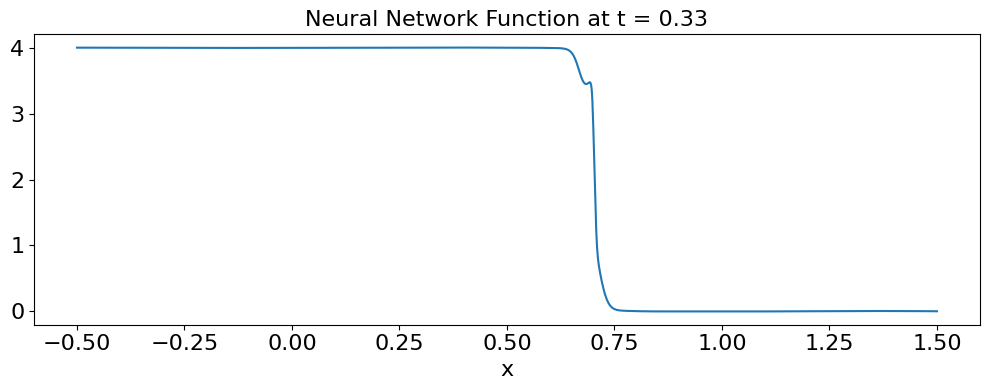

Grade 0, Iter 4100, loss_eqn: 0.111382, loss_eqn_from_kh: 0.111382, loss_l1: 0.550906, loss_ibc: 0.001375
Grade 0, Iter 4200, loss_eqn: 0.114559, loss_eqn_from_kh: 0.114559, loss_l1: 0.545753, loss_ibc: 0.001372
Grade 0, Iter 4300, loss_eqn: 0.102693, loss_eqn_from_kh: 0.102693, loss_l1: 0.543929, loss_ibc: 0.001391
Grade 0, Iter 4400, loss_eqn: 0.097415, loss_eqn_from_kh: 0.097416, loss_l1: 0.541212, loss_ibc: 0.001427
Grade 0, Iter 4500, loss_eqn: 0.094012, loss_eqn_from_kh: 0.094012, loss_l1: 0.540196, loss_ibc: 0.001413
Grade 0, Iter 4600, loss_eqn: 0.094430, loss_eqn_from_kh: 0.094430, loss_l1: 0.536325, loss_ibc: 0.001436
Grade 0, Iter 4700, loss_eqn: 0.090131, loss_eqn_from_kh: 0.090131, loss_l1: 0.534051, loss_ibc: 0.001462
Grade 0, Iter 4800, loss_eqn: 0.089429, loss_eqn_from_kh: 0.089429, loss_l1: 0.532392, loss_ibc: 0.001460
Grade 0, Iter 4900, loss_eqn: 0.090492, loss_eqn_from_kh: 0.090492, loss_l1: 0.530646, loss_ibc: 0.001474
Train time for stage1: 760.214022 seconds

Plo

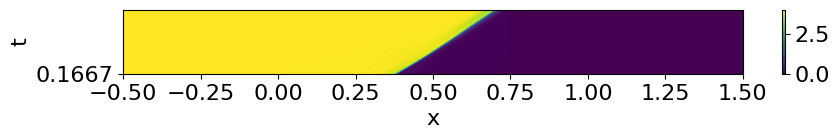

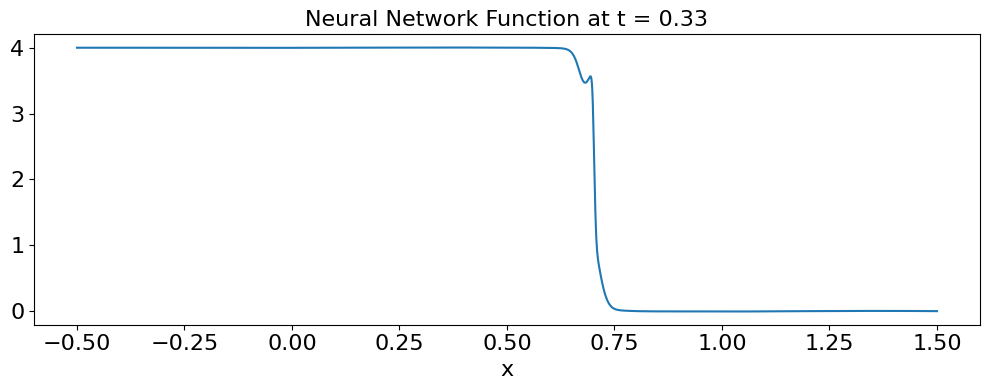

Adding grade 1 with hidden dims [64, 64, 64, 64, 64]

Training segment [0.3333, 0.5000]
Skipping pre-training as pre_epochs is set to 0.

Starting Train Stage with MGDL

Stage 1: Sequential Grade Training

Training Grade 0
The largest W^{1,inf} norm of k_h coeffs is 3.176214
Grade 0, Iter 0, lambda_ic: 9.196281, lambda_bc: 9.758161, lambda_eqn: 1.178840
Grade 0, Iter 0, loss_eqn: 1.832089, loss_eqn_from_kh: 1.832081, loss_l1: 1.832081, loss_ibc: 27.511147


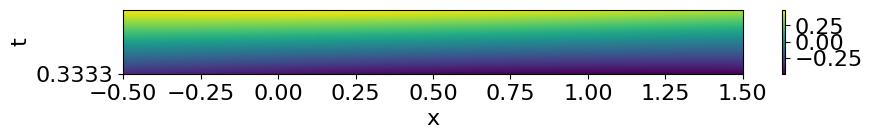

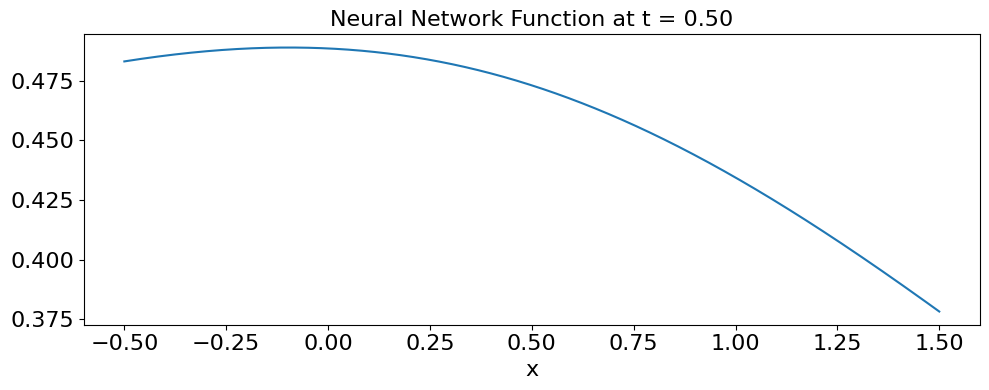

Grade 0, Iter 100, loss_eqn: 1.031719, loss_eqn_from_kh: 1.031718, loss_l1: 1.031735, loss_ibc: 1.019330
Grade 0, Iter 200, loss_eqn: 0.769287, loss_eqn_from_kh: 0.769285, loss_l1: 0.794464, loss_ibc: 0.525980
Grade 0, Iter 300, loss_eqn: 0.798003, loss_eqn_from_kh: 0.797999, loss_l1: 0.905358, loss_ibc: 0.140269
Grade 0, Iter 400, loss_eqn: 0.453908, loss_eqn_from_kh: 0.453907, loss_l1: 0.751599, loss_ibc: 0.036255
Grade 0, Iter 500, loss_eqn: 0.296297, loss_eqn_from_kh: 0.296296, loss_l1: 0.705954, loss_ibc: 0.015844
Grade 0, Iter 600, loss_eqn: 0.288188, loss_eqn_from_kh: 0.288188, loss_l1: 0.710124, loss_ibc: 0.011974
Grade 0, Iter 700, loss_eqn: 0.281386, loss_eqn_from_kh: 0.281387, loss_l1: 0.694967, loss_ibc: 0.011182
Grade 0, Iter 800, loss_eqn: 0.288340, loss_eqn_from_kh: 0.288341, loss_l1: 0.700571, loss_ibc: 0.011154
Grade 0, Iter 900, loss_eqn: 0.266550, loss_eqn_from_kh: 0.266550, loss_l1: 0.682814, loss_ibc: 0.011130
Grade 0, Iter 1000, lambda_ic: 10.156989, lambda_bc: 12

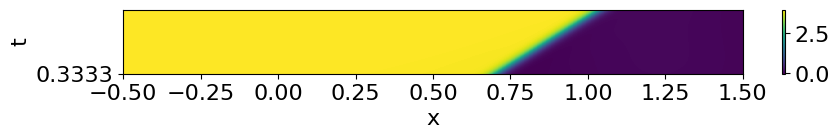

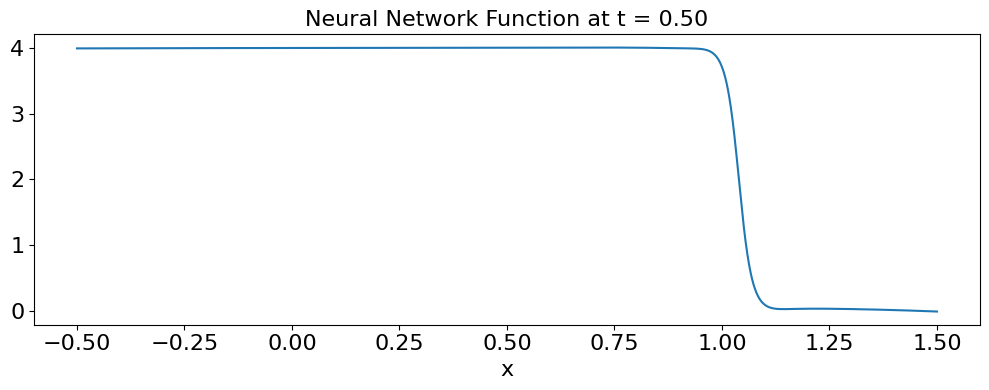

Grade 0, Iter 1100, loss_eqn: 0.278918, loss_eqn_from_kh: 0.278918, loss_l1: 0.700880, loss_ibc: 0.010403
Grade 0, Iter 1200, loss_eqn: 0.277004, loss_eqn_from_kh: 0.277004, loss_l1: 0.698780, loss_ibc: 0.010380
Grade 0, Iter 1300, loss_eqn: 0.277377, loss_eqn_from_kh: 0.277377, loss_l1: 0.697167, loss_ibc: 0.010369
Grade 0, Iter 1400, loss_eqn: 0.277307, loss_eqn_from_kh: 0.277307, loss_l1: 0.695410, loss_ibc: 0.010129
Grade 0, Iter 1500, loss_eqn: 0.280725, loss_eqn_from_kh: 0.280726, loss_l1: 0.702124, loss_ibc: 0.010385
Grade 0, Iter 1600, loss_eqn: 0.262068, loss_eqn_from_kh: 0.262068, loss_l1: 0.685000, loss_ibc: 0.010385
Grade 0, Iter 1700, loss_eqn: 0.278384, loss_eqn_from_kh: 0.278384, loss_l1: 0.700184, loss_ibc: 0.010218
Grade 0, Iter 1800, loss_eqn: 0.275990, loss_eqn_from_kh: 0.275990, loss_l1: 0.700282, loss_ibc: 0.009940
Grade 0, Iter 1900, loss_eqn: 0.277417, loss_eqn_from_kh: 0.277417, loss_l1: 0.708237, loss_ibc: 0.009938
Grade 0, Iter 2000, lambda_ic: 10.377535, lamb

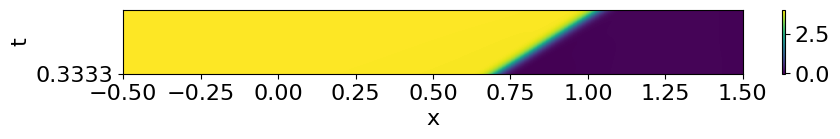

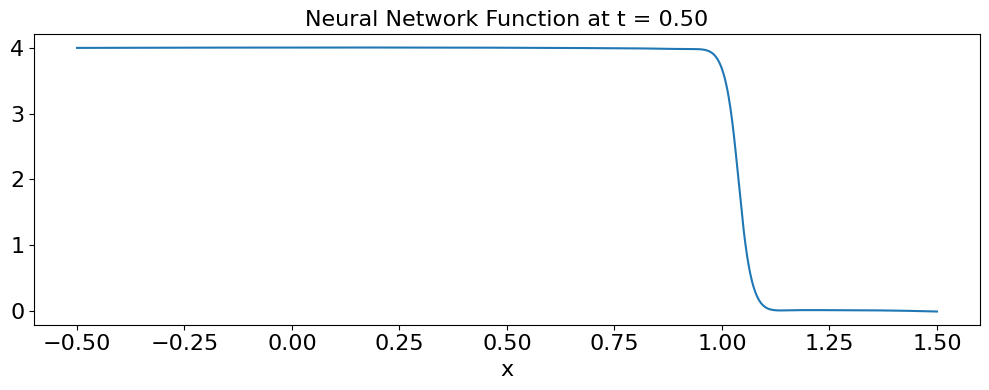

Grade 0, Iter 2100, loss_eqn: 0.262666, loss_eqn_from_kh: 0.262665, loss_l1: 0.689270, loss_ibc: 0.009898
Grade 0, Iter 2200, loss_eqn: 0.260921, loss_eqn_from_kh: 0.260921, loss_l1: 0.690351, loss_ibc: 0.009452
Grade 0, Iter 2300, loss_eqn: 0.260901, loss_eqn_from_kh: 0.260899, loss_l1: 0.688578, loss_ibc: 0.009548
Grade 0, Iter 2400, loss_eqn: 0.267152, loss_eqn_from_kh: 0.267153, loss_l1: 0.696218, loss_ibc: 0.009211
Grade 0, Iter 2500, loss_eqn: 0.252533, loss_eqn_from_kh: 0.252533, loss_l1: 0.685454, loss_ibc: 0.009099
Grade 0, Iter 2600, loss_eqn: 0.251701, loss_eqn_from_kh: 0.251700, loss_l1: 0.682943, loss_ibc: 0.008693
Grade 0, Iter 2700, loss_eqn: 0.247292, loss_eqn_from_kh: 0.247292, loss_l1: 0.681840, loss_ibc: 0.008337
Grade 0, Iter 2800, loss_eqn: 0.244734, loss_eqn_from_kh: 0.244732, loss_l1: 0.681939, loss_ibc: 0.007669
Grade 0, Iter 2900, loss_eqn: 0.242550, loss_eqn_from_kh: 0.242550, loss_l1: 0.681101, loss_ibc: 0.007274
Grade 0, Iter 3000, lambda_ic: 10.475409, lamb

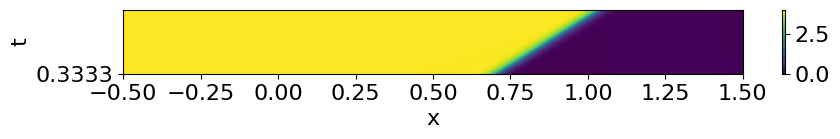

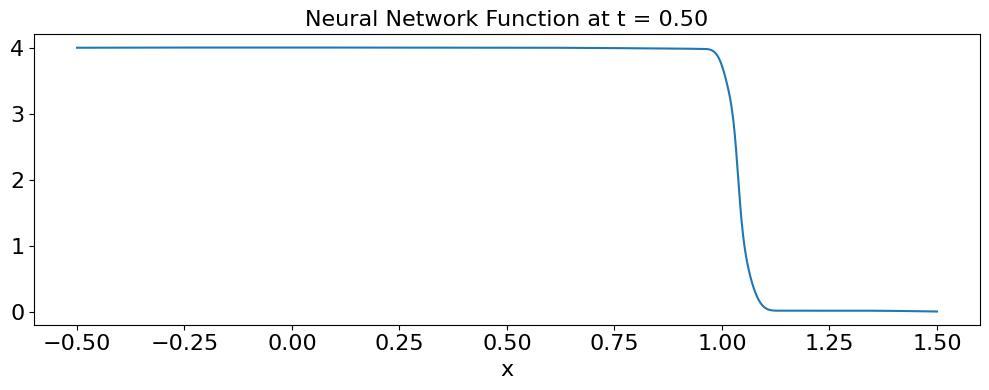

Grade 0, Iter 3100, loss_eqn: 0.234700, loss_eqn_from_kh: 0.234700, loss_l1: 0.674436, loss_ibc: 0.006273
Grade 0, Iter 3200, loss_eqn: 0.229552, loss_eqn_from_kh: 0.229552, loss_l1: 0.666081, loss_ibc: 0.005559
Grade 0, Iter 3300, loss_eqn: 0.223513, loss_eqn_from_kh: 0.223513, loss_l1: 0.651553, loss_ibc: 0.004744
Grade 0, Iter 3400, loss_eqn: 0.222365, loss_eqn_from_kh: 0.222364, loss_l1: 0.635702, loss_ibc: 0.003883
Grade 0, Iter 3500, loss_eqn: 0.206879, loss_eqn_from_kh: 0.206879, loss_l1: 0.609616, loss_ibc: 0.003411
Grade 0, Iter 3600, loss_eqn: 0.196012, loss_eqn_from_kh: 0.196012, loss_l1: 0.587399, loss_ibc: 0.002709
Grade 0, Iter 3700, loss_eqn: 0.184482, loss_eqn_from_kh: 0.184482, loss_l1: 0.570025, loss_ibc: 0.002091
Grade 0, Iter 3800, loss_eqn: 0.175300, loss_eqn_from_kh: 0.175301, loss_l1: 0.553042, loss_ibc: 0.001854
Grade 0, Iter 3900, loss_eqn: 0.181928, loss_eqn_from_kh: 0.181929, loss_l1: 0.541471, loss_ibc: 0.000966
Grade 0, Iter 4000, lambda_ic: 13.990135, lamb

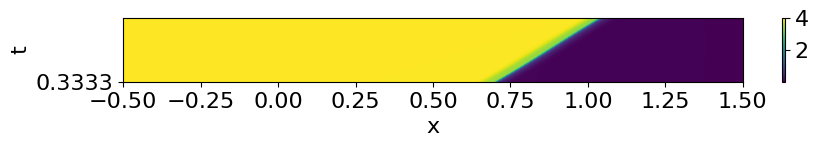

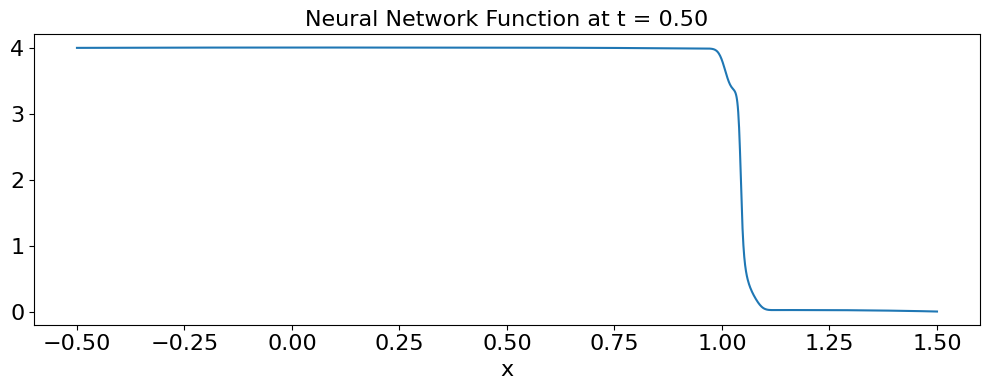

Grade 0, Iter 4100, loss_eqn: 0.159392, loss_eqn_from_kh: 0.159392, loss_l1: 0.528037, loss_ibc: 0.000721
Grade 0, Iter 4200, loss_eqn: 0.154991, loss_eqn_from_kh: 0.154991, loss_l1: 0.516069, loss_ibc: 0.000625
Grade 0, Iter 4300, loss_eqn: 0.153921, loss_eqn_from_kh: 0.153921, loss_l1: 0.513626, loss_ibc: 0.000620
Grade 0, Iter 4400, loss_eqn: 0.151643, loss_eqn_from_kh: 0.151643, loss_l1: 0.509061, loss_ibc: 0.000493
Grade 0, Iter 4500, loss_eqn: 0.150282, loss_eqn_from_kh: 0.150282, loss_l1: 0.506124, loss_ibc: 0.000498
Grade 0, Iter 4600, loss_eqn: 0.148736, loss_eqn_from_kh: 0.148736, loss_l1: 0.506682, loss_ibc: 0.000495
Grade 0, Iter 4700, loss_eqn: 0.148158, loss_eqn_from_kh: 0.148158, loss_l1: 0.505248, loss_ibc: 0.000489
Grade 0, Iter 4800, loss_eqn: 0.147593, loss_eqn_from_kh: 0.147593, loss_l1: 0.504707, loss_ibc: 0.000489
Grade 0, Iter 4900, loss_eqn: 0.147371, loss_eqn_from_kh: 0.147370, loss_l1: 0.504780, loss_ibc: 0.000489
Train time for stage1: 764.179710 seconds

Plo

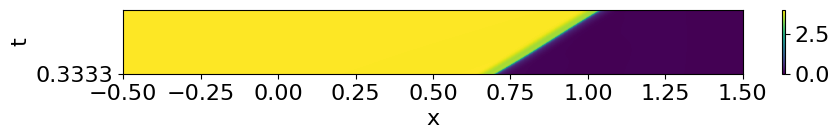

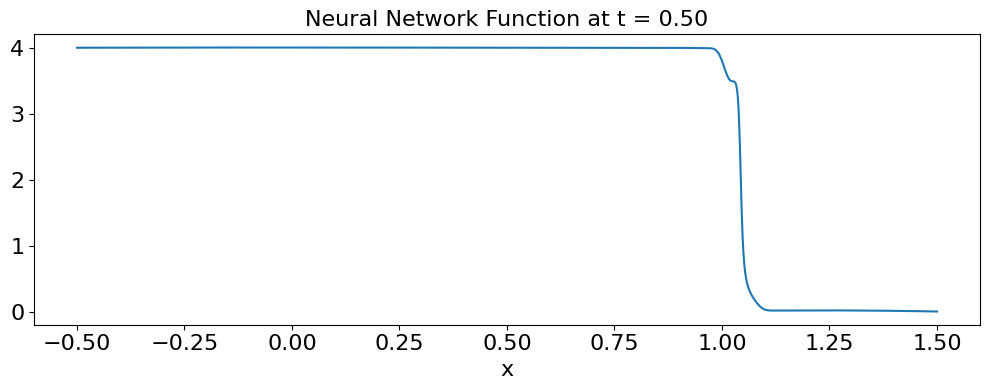


Plotting combined output across all segments from t=0 to total_t_max


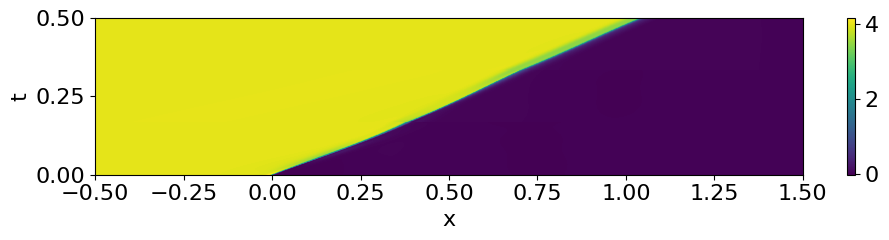

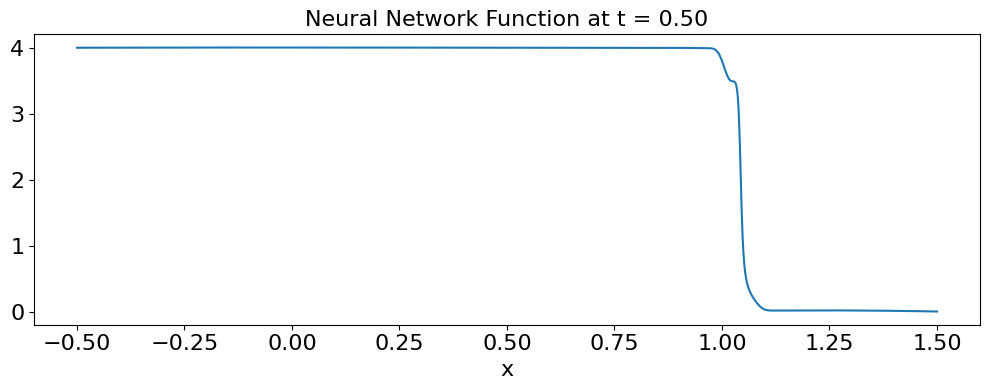

In [4]:
seq_trainer.train_seq()

In [14]:
offsets_bin = jnp.array([[int(b) for b in f'{i:02b}'] for i in range(4)], dtype=jnp.float32)  # (8,3) binary 000 to 111


In [8]:
N_t, N_x, N_y = 3, 3, 3  # Small number of divisions for testing
t_min, t_max = 0.0, 1.0
x_min, x_max = -1.0, 1.0
y_min, y_max = -1.0, 1.0
gauss_order = 5  # Default

pwp = PiecewiseLinearPolynomialsHex(N_t, N_x, N_y, t_min, t_max, x_min, x_max, y_min, y_max, gauss_order)

In [12]:
partitions = pwp.partitions[pwp.element_indices]
t_low = partitions[:, 0, 0]
x_low = partitions[:, 0, 1]
y_low = partitions[:, 0, 2]
t_high = partitions[:, -1, 0]
x_high = partitions[:, -1, 1]
y_high = partitions[:, -1, 2]
d_t = (t_high - t_low)
d_x = (x_high - x_low)
d_y = (y_high - y_low)

In [13]:
d_t

Array([0.33333334, 0.33333334, 0.33333334, ..., 0.3333333 , 0.3333333 ,
       0.3333333 ], dtype=float32)